# Output Head Architecture & Ordinal Regression Ablation Benchmark (Hypothesis H3)

[![PyTorch](https://img.shields.io/badge/PyTorch-2.0%2B-EE4C2C.svg?logo=pytorch)](https://pytorch.org/)
[![Hardware: T4/L4/A100](https://img.shields.io/badge/Hardware-Colab%20T4%2FL4%2FA100-success.svg)]()
[![Domain: Medical Computer Vision](https://img.shields.io/badge/Domain-Medical%20Computer%20Vision-blue.svg)]()
[![Task: 5-Grade Ordinal DR](https://img.shields.io/badge/Task-5--Grade%20Ordinal%20DR-informational.svg)]()

---

## Executive Summary & Scientific Rationale

This notebook implements the systematic **5-Round End-to-End Head Ablation Benchmark** evaluating 5 output loss formulations on a standardized **ResNet-50** backbone ($512 \times 512$ resolution) for 5-class Diabetic Retinopathy (DR) grading:
1. **Nominal Softmax + Categorical Cross-Entropy (Softmax_CE)**: Standard multiclass classification baseline.
2. **Nominal Softmax + Continuous QWK Loss (Softmax_QWK)**: Softmax with differentiable quadratic penalty optimization and step-level dynamic loss warmup.
3. **Consistent Rank Logits (CORAL)**: Shared linear weight vector with independent monotonic threshold biases $b_0..b_3$ and isotonic probability projection.
4. **Conditional Ordinal Regression Neural Network (CORN)**: Conditional probability formulation $P(y > k \mid y \ge k)$ with full computational graph gradient safeguards.
5. **Cumulative Link Model + Continuous QWK Loss (CLM_QWK - Champion Architecture)**: Complementary log-log ($\text{clog-log}$) link function with strictly monotonic cutpoints $\theta_1 < \theta_2 < \theta_3 < \theta_4$ (via Softplus parameterization) and continuous step-level QWK loss warmup ($\lambda: 0.0 \to 1.2$).

### Controlled Experimental Protocol:
- **Strictly Controlled Backbone**: All 5 heads are paired with an identical **ResNet-50** feature extractor ($512 \times 512$ resolution, Green-channel Ben Graham contrast enhancement, AdamW optimizer, Cosine Annealing scheduler).
- **Independent End-to-End Optimization**: Each head is trained from scratch together with its own ResNet-50 backbone across 5 distinct training loops (zero shared latent caching, eliminating inter-head bias).
- **Zero VRAM Leak Across Rounds**: Models are automatically offloaded to CPU memory and VRAM caches are cleared (`torch.cuda.empty_cache()` + `gc.collect()`) after each round, eliminating CUDA OOM risks on Colab T4 / L4.
- **Strict Monotonic Gradient Propagation**: CLM_QWK eliminates redundant `F.relu()` truncation, directly computing strictly positive interval probabilities from softplus cutpoints without gradient suppression.
- **Safe DDP/DP Checkpoint Loading**: Unwraps `module.` prefixes automatically when restoring best model weights.
- **Class-Balanced Loss Weighting**: Automatically computes inverse-frequency class weights from the training cohort to combat clinical grade imbalance (Grade 0 vs Grade 1/3/4).
- **Step-Level Dynamic QWK Warmup**: For `Softmax_QWK` and `CLM_QWK`, the quadratic penalty weight $\lambda$ increases continuously at each batch step from $0.0 \to \lambda_{\text{target}}$ during the warmup phase.
- **Early Stopping Protocol**: Automatically monitors Validation QWK with configurable patience (`PATIENCE_EARLY_STOP = 15`) and restores the best checkpoint.
- **Zero Patient Leakage**: Evaluated on a 15% In-Domain Patient-Grouped Held-out Test Set.

---

## Table of Contents
1. [Environment Setup & Global Configuration](#1-environment-setup--global-configuration)
2. [Data Pipeline & Preprocessing](#2-data-pipeline--preprocessing)
3. [ResNet-50 Feature Extractor & 5 Output Heads](#3-resnet-50-feature-extractor--5-output-heads)
4. [Clinical Metrics & PyTorch DRHeadTrainer](#4-clinical-metrics--pytorch-drheadtrainer)
5. [Systematic 5-Round End-to-End Ablation Benchmark](#5-systematic-5-round-end-to-end-ablation-benchmark)
6. [Publication-Quality Head Ablation Visualization Suite (Figs 1, 3, 4, 6, 7)](#6-publication-quality-head-ablation-visualization-suite)

In [61]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Environment Setup & Global Configuration

In [62]:
import os
import sys
import gc
import time
import json
import logging
from pathlib import Path, PureWindowsPath
from typing import List, Tuple, Union, Dict, Optional, Any

# --- Deep Learning & PyTorch Core ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

# --- Scientific Computing & Image Processing ---
import cv2
cv2.setNumThreads(0)  # Mandatory: prevent OpenCV multithreading contention in DataLoader workers
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    cohen_kappa_score,
    confusion_matrix,
    accuracy_score,
    recall_score,
    roc_curve,
    roc_auc_score,
    auc,
)

# --- Visualization & Academic Plotting ---
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from matplotlib.patches import Patch, Rectangle, FancyBboxPatch

# Setup module logger with singleton StreamHandler
logger = logging.getLogger("HeadAblation")
if not logger.handlers:
    handler = logging.StreamHandler()
    formatter = logging.Formatter("[%(levelname)s | %(asctime)s | HeadAblation] %(message)s")
    handler.setFormatter(formatter)
    logger.addHandler(handler)
logger.setLevel(logging.INFO)

# Set random seed for reproducibility
def set_seed(seed: int = 42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Hardware Detection & Mixed Precision Capability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
amp_dtype = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else torch.float16

print(f"[HARDWARE] Active Compute Device: {device} ({gpu_name})")
print(f"[PRECISION] AMP Mixed Precision Dtype: {amp_dtype}")


[HARDWARE] Active Compute Device: cuda (NVIDIA L4)
[PRECISION] AMP Mixed Precision Dtype: torch.bfloat16


In [63]:
# # ==============================================================================
# # OPTIONAL: HIGH-SPEED DATASET EXTRACTION TO LOCAL SSD
# # ==============================================================================
# # 1. Automatically check and mount Google Drive if not connected
# if not os.path.exists("/content/drive/MyDrive"):
#     try:
#         from google.colab import drive
#         drive.mount("/content/drive")
#     except ImportError:
#         pass

# # 2. Configure path settings
# zip_source = "/content/drive/MyDrive/native_cropped.zip"  # Zip archive path on Drive
# extract_dest = "/content/dataset_local"                 # Local high-speed VM SSD directory

# # 3. Extract archive to local SSD if zip exists and destination is not yet populated
# if os.path.exists(zip_source) and not os.path.exists(extract_dest):
#     os.makedirs(extract_dest, exist_ok=True)
#     print(f"Extracting dataset from Google Drive to local SSD: '{extract_dest}'...")
#     t0 = time.time()
#     get_ipython().system('unzip -q "$zip_source" -d "$extract_dest"')
#     print(f"-> Extraction completed in {time.time() - t0:.1f} seconds!")


In [64]:
# # 1. Giải nén dataset gốc như bình thường
# !unzip -q "/content/drive/MyDrive/native_cropped.zip" -d "/content/dataset_local"

# # 2. Giải nén thẳng cache .npy đã nén sẵn vào local_run
# !mkdir -p /content/local_run
# !unzip -q "/content/drive/MyDrive/cache_head_ablation.zip" -d "/"
# print("-> Cache .npy đã sẵn sàng, bỏ qua bước warm_cache!")

In [65]:
# ==============================================================================
# PATH CONFIGURATION: DECOUPLING LOCAL SSD EXECUTION FROM GOOGLE DRIVE
# ==============================================================================
# 1. Google Drive persistent storage root (for final one-time synchronization)
DRIVE_ROOT = '/content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model'

# 2. Local SSD execution root (eliminates Drive FUSE network I/O latency completely)
LOCAL_RUN_ROOT = '/content/local_run'
os.makedirs(LOCAL_RUN_ROOT, exist_ok=True)

# 3. Dataset root path (points to extracted local SSD or fallback dataset directory)
DATASET_ROOT = '/content/dataset_local'
RESULT_ROOT = LOCAL_RUN_ROOT

print(f"[PATHS] Persistent Google Drive Root: '{DRIVE_ROOT}'")
print(f"[PATHS] Local SSD Fast Runtime Root : '{LOCAL_RUN_ROOT}'")
print(f"[PATHS] Active Dataset Source Root  : '{DATASET_ROOT}'")


[PATHS] Persistent Google Drive Root: '/content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model'
[PATHS] Local SSD Fast Runtime Root : '/content/local_run'
[PATHS] Active Dataset Source Root  : '/content/dataset_local'


In [66]:
# ==============================================================================
# 1.1 GLOBAL EXPERIMENTAL CONFIGURATION & HYPERPARAMETERS (TWEAK HERE)
# ==============================================================================

# --- Execution Mode & Dataset Root ---
SMOKE_TEST = False  # Set to True for rapid sanity check (2 epochs), False for full official ablation (25 epochs)

# Output directories on LOCAL SSD for zero-latency I/O operations
CHECKPOINT_DIR_HEAD = f"{DRIVE_ROOT}/checkpoints_head_ablation"
RESULTS_DIR_HEAD    = f"{DRIVE_ROOT}/results/head_ablation"
FIGURES_DIR         = f"{DRIVE_ROOT}/results/figures"
CACHE_DIR_HEAD      = f"{LOCAL_RUN_ROOT}/cache_head_ablation"

os.makedirs(CHECKPOINT_DIR_HEAD, exist_ok=True)
os.makedirs(RESULTS_DIR_HEAD, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(CACHE_DIR_HEAD, exist_ok=True)

# --- Training Hyperparameters ---
IMG_SIZE             = 512     # Standardized image resolution 512x512
BATCH_SIZE           = 48      # Optimized for 16GB T4 / 24GB L4 / 40GB A100 (decrease to 16 if VRAM is constrained)
ABLATION_EPOCHS      = 2 if SMOKE_TEST else 25  # Number of training epochs per head
LEARNING_RATE        = 1e-4    # Initial learning rate for AdamW
WEIGHT_DECAY         = 1e-3    # Weight decay for AdamW
MIN_LR               = 1e-6    # Minimum learning rate for CosineAnnealingLR
PATIENCE_EARLY_STOP  = 15       # Early stopping patience based on Validation QWK

# --- Class Weighting & QWK Loss Warmup Settings ---
# Advisor HD_4 Part 1: Retain naturally calibrated probabilities for screening; disable class-weight distortion
USE_CLASS_WEIGHTS    = False   # Set to False to preserve natural posterior calibration for threshold calibration
# Scaled down from 1.2/1.0 to 0.4 to prevent gradient shocks from batch soft confusion matrices (HD_4 Part 4)
TARGET_QWK_WEIGHT    = 0.4     # Target lambda for Continuous QWK Loss in Champion CLM_QWK
SOFTMAX_QWK_TARGET   = 0.4     # Target lambda for Softmax_QWK head
# Extended linear warmup from 5 to 15 epochs to stabilize early feature manifold formation (HD_4 Part 4)
QWK_WARMUP_EPOCHS    = 15 if not SMOKE_TEST else 1  # Epochs over which lambda warms up continuously from 0.0 -> TARGET

# --- DataLoader & Hardware Performance Knobs ---
NUM_WORKERS          = min(4, os.cpu_count() or 2)
PIN_MEMORY           = torch.cuda.is_available()
USE_AMP              = True    # Automatic Mixed Precision (float16 on T4, bfloat16 on L4/A100)

# --- 5 Output Heads for Systematic End-to-End Ablation ---
EVALUATED_HEADS = [
    "Softmax_CE",   # Head 1: Nominal Softmax + Cross-Entropy (Baseline)
    "Softmax_QWK",  # Head 2: Nominal Softmax + Hybrid QWK Loss (with linear warmup)
    "CORAL",        # Head 3: Consistent Rank Logits (Binary Ordinal with Isotonic Projection)
    "CORN",         # Head 4: Conditional Ordinal Regression (Safeguarded BCE)
    "CLM_QWK"       # Head 5: Cumulative Link Model (clog-log + Softplus monotonic cutpoints + QWK warmup)
]

print(f"Evaluated Output Heads: {EVALUATED_HEADS}")
print(f"Image Resolution: {IMG_SIZE}x{IMG_SIZE} | Batch Size: {BATCH_SIZE} | Epochs per Head: {ABLATION_EPOCHS}")
print(f"Class-Balanced Weighting: {USE_CLASS_WEIGHTS} | Early Stopping Patience: {PATIENCE_EARLY_STOP}")
print(f"QWK Loss Linear Warmup: 0.0 -> {TARGET_QWK_WEIGHT} over {QWK_WARMUP_EPOCHS} epochs")
print(f"Execution Mode: {'SMOKE TEST (Sanity Check: 2 Epochs)' if SMOKE_TEST else 'FULL END-TO-END ABLATION (25 Epochs)'}")


Evaluated Output Heads: ['Softmax_CE', 'Softmax_QWK', 'CORAL', 'CORN', 'CLM_QWK']
Image Resolution: 512x512 | Batch Size: 48 | Epochs per Head: 25
Class-Balanced Weighting: False | Early Stopping Patience: 15
QWK Loss Linear Warmup: 0.0 -> 0.4 over 15 epochs
Execution Mode: FULL END-TO-END ABLATION (25 Epochs)


In [67]:
NUM_WORKERS


4

In [68]:
# ==============================================================================
# 1.2 PUBLICATION STYLE CONFIGURATION & UNIFIED NORMALIZATION (DRY PRINCIPLE)
# ==============================================================================
def configure_publication_style():
    plt.rcParams.update({
        'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica', 'Liberation Sans'],
        'font.family': 'sans-serif',
        'font.size': 10.5,
        'axes.labelsize': 11.5,
        'axes.titlesize': 12.5,
        'axes.titleweight': 'bold',
        'axes.labelweight': 'bold',
        'xtick.labelsize': 10.0,
        'ytick.labelsize': 10.0,
        'legend.fontsize': 9.5,
        'legend.title_fontsize': 10.5,
        'figure.titlesize': 14.0,
        'figure.titleweight': 'bold',
        'axes.linewidth': 1.1,
        'axes.edgecolor': '#2d3748',
        'grid.linewidth': 0.7,
        'grid.alpha': 0.45,
        'grid.linestyle': '--',
        'grid.color': '#cbd5e1',
        'mathtext.fontset': 'dejavusans',
        'figure.dpi': 300,
        'savefig.dpi': 300,
        'savefig.bbox': 'tight',
        'savefig.pad_inches': 0.08
    })
    sns.set_theme(style="whitegrid", rc={'grid.linestyle': '--', 'grid.alpha': 0.45})

configure_publication_style()

# Academic Color Palette Definitions (Emphasis Technique: 1 Color + Gray)
C_NAVY     = "#1a365d"  # Baseline Softmax_CE
C_TEAL     = "#0d9488"  # Champion Model CLM_QWK
C_ORANGE   = "#e65100"  # CORAL / Grade 1 Emphasis
C_CRIMSON  = "#c53030"  # Grade 3 Emphasis / Violations
C_PURPLE   = "#6b21a8"  # Monotonic Cutpoints theta
C_GRAY     = "#94a3b8"  # Secondary / Neutral Bars
C_DARKGRAY = "#475569"  # Annotations
C_EMERALD  = "#16a34a"  # High Accuracy / Compliance
C_AMBER    = "#d97706"  # CORN / Softmax_QWK Highlights

# --- UNIFIED NORMALIZATION HELPER (DRY PRINCIPLE) ---
def normalize_fundus_tensor(images: torch.Tensor, device: Union[str, torch.device] = "cuda") -> torch.Tensor:
    """
    Standardizes uint8 [0..255] or float tensors using ImageNet Z-score constants directly on GPU.
    Eliminates duplicated normalization logic across training and visualization pipelines.
    """
    dev = torch.device(device)
    if images.dtype == torch.uint8:
        mean_gpu = torch.tensor([0.485, 0.456, 0.406], device=dev, dtype=torch.float32).view(1, 3, 1, 1)
        std_gpu  = torch.tensor([0.229, 0.224, 0.225], device=dev, dtype=torch.float32).view(1, 3, 1, 1)
        return images.to(dev, non_blocking=True).float().div_(255.0).sub_(mean_gpu).div_(std_gpu)
    return images.to(dev, non_blocking=True)


## 2. Multi-Center Dataset Ingestion, Preprocessing, & Class Weights

In [69]:
# ==============================================================================
# 2.1 METADATA INGESTION & BALANCED CLASS WEIGHTS COMPUTATION
# ==============================================================================

def load_dataset_metadata(data_dir: str, smoke_test: bool = False):
    # Determine candidate file paths with safe fallbacks

    train_path = os.path.join(data_dir, "train_balanced_metadata.csv")
    val_path  = os.path.join(data_dir, "val_metadata.csv")
    test_path = os.path.join(data_dir, "test_metadata.csv")

    train_df = pd.read_csv(train_path)
    val_df   = pd.read_csv(val_path)
    test_df  = pd.read_csv(test_path)

    if smoke_test:
        train_df = train_df.groupby("diagnosis").head(20).reset_index(drop=True)
        val_df   = val_df.groupby("diagnosis").head(10).reset_index(drop=True)
        test_df  = test_df.groupby("diagnosis").head(15).reset_index(drop=True)

    logger.info(f"Loaded splits from '{data_dir}': Train={len(train_df):,} | Val={len(val_df):,} | Test={len(test_df):,}")
    return train_df, val_df, test_df

train_metadata, val_metadata, test_metadata = load_dataset_metadata(DATASET_ROOT, smoke_test=SMOKE_TEST)

# Compute inverse-frequency balanced class weights from training metadata
if USE_CLASS_WEIGHTS:
    class_counts = train_metadata["diagnosis"].value_counts().sort_index().values
    total_samples = len(train_metadata)
    raw_weights = total_samples / (5.0 * np.maximum(class_counts, 1).astype(float))
    norm_weights = raw_weights / raw_weights.mean()  # Normalize mean to 1.0 to prevent gradient scale drift
    class_weights_tensor = torch.tensor(norm_weights, dtype=torch.float32).to(device)
    logger.info(f"Computed Balanced Class Weights (G0..G4): {norm_weights.round(3).tolist()}")
else:
    class_weights_tensor = None
    logger.info("Class weights disabled (Uniform loss scaling).")


[INFO | 2026-09-02 18:17:25,802 | HeadAblation] Loaded splits from '/content/dataset_local': Train=9,079 | Val=8,238 | Test=8,075
INFO:HeadAblation:Loaded splits from '/content/dataset_local': Train=9,079 | Val=8,238 | Test=8,075
[INFO | 2026-09-02 18:17:25,807 | HeadAblation] Class weights disabled (Uniform loss scaling).
INFO:HeadAblation:Class weights disabled (Uniform loss scaling).


In [70]:
# ==============================================================================
# 2.2 GREEN-CHANNEL PREPROCESSING, UNCOMPRESSED NPY CACHING, & WARM-UP ENGINE
# ==============================================================================

def apply_green_channel_ablation(img_rgb: np.ndarray, ablation_mode: str = "ben_graham_green") -> np.ndarray:
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    denoised = cv2.bilateralFilter(bgr, d=9, sigmaColor=75, sigmaSpace=75)
    b, g, r = cv2.split(denoised)

    if ablation_mode == "ben_graham_green":
        blurred = cv2.GaussianBlur(g, (0, 0), 30)
        adjusted = cv2.addWeighted(g, 4, blurred, -4, 128)
        processed = cv2.merge([adjusted, adjusted, adjusted])
    elif ablation_mode == "clahe_green":
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enhanced_g = clahe.apply(g)
        processed = cv2.merge([enhanced_g, enhanced_g, enhanced_g])
    else:
        processed = cv2.merge([g, g, g])

    return cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)

class ResNetFundusDataset(Dataset):
    """
    High-Performance PyTorch Dataset serving standardized 512x512 fundus images.
    Features Ultra-Fast Uncompressed .npy Caching on Local SSD:
      1. Loads preprocessed uint8 512x512 array from .npy cache (<1 ms on local SSD).
      2. If .npy is missing (cold start), preprocesses and auto-saves uncompressed .npy to disk.
      3. Transmits uint8 tensors across DataLoader workers to slash shared memory IPC bandwidth.
      4. Explicitly logs any cache I/O errors instead of silently suppressing them.
    """
    def __init__(
        self,
        df: pd.DataFrame,
        img_size: int = IMG_SIZE,
        split: str = "train",
        ablation_mode: str = "ben_graham_green",
        cache_dir: Optional[str] = None
    ):
        self.df = df.reset_index(drop=True)
        self.records = self.df.to_dict("records")
        self.img_size = img_size
        self.split = split
        self.ablation_mode = ablation_mode
        self.is_train = (split == "train")
        self.cache_dir = cache_dir

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        row = self.records[idx]
        label = int(row.get("diagnosis", 0))
        dataset_key = row.get("dataset_key", "default")
        native_path_str = str(row.get("native_path", row.get("raw_full_path", "")))
        img_id = PureWindowsPath(native_path_str).stem if native_path_str else str(row.get("image_id", idx))

        cache_file = os.path.join(self.cache_dir, dataset_key, f"{img_id}.npy") if self.cache_dir else None
        processed_rgb = None

        # 1. Check if uncompressed .npy cache exists on local SSD (Instant load in < 1 ms)
        if cache_file and os.path.exists(cache_file):
            try:
                processed_rgb = np.load(cache_file)
            except Exception as e:
                logger.warning(f"[CACHE] Read failure on '{cache_file}': {e}. Recomputing from raw source.")
                processed_rgb = None

        # 2. Cache Miss (Cold Start): Preprocess on-the-fly and save uncompressed .npy to local SSD
        if processed_rgb is None:
            if os.path.exists(native_path_str):
                img_bgr = cv2.imread(native_path_str)
                img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) if img_bgr is not None else np.full((self.img_size, self.img_size, 3), 128, dtype=np.uint8)
            else:
                img_rgb = np.full((self.img_size, self.img_size, 3), 128, dtype=np.uint8)

            processed_rgb = apply_green_channel_ablation(img_rgb, self.ablation_mode)

            if processed_rgb.shape[0] != self.img_size or processed_rgb.shape[1] != self.img_size:
                processed_rgb = cv2.resize(processed_rgb, (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)

            # Auto-save uncompressed .npy to local SSD (eliminates CPU compression bottleneck)
            if cache_file:
                try:
                    os.makedirs(os.path.dirname(cache_file), exist_ok=True)
                    np.save(cache_file, processed_rgb)
                except Exception as e:
                    logger.warning(f"[CACHE] Write failure on '{cache_file}': {e}")

        # 3. Spatial Augmentation (Train mode only, applied dynamically in RAM on cached array)
        augmented_rgb = processed_rgb.copy()
        if self.is_train:
            if np.random.rand() > 0.5:
                augmented_rgb = np.fliplr(augmented_rgb)
            if np.random.rand() > 0.5:
                augmented_rgb = np.flipud(augmented_rgb)
            k_rot = np.random.choice([0, 1, 2, 3])
            if k_rot > 0:
                augmented_rgb = np.rot90(augmented_rgb, k_rot)

        # 4. uint8 tensor (C, H, W) for zero-overhead IPC transmission
        tensor_u8 = torch.from_numpy(np.ascontiguousarray(augmented_rgb)).permute(2, 0, 1)

        return {
            "image": tensor_u8,
            "label": torch.tensor(label, dtype=torch.long),
            "patient_id": row.get("patient_id", "unknown"),
            "dataset_key": dataset_key
        }

# Instantiate Datasets & Optimized DataLoaders on LOCAL SSD
train_dataset = ResNetFundusDataset(train_metadata, img_size=IMG_SIZE, split="train", cache_dir=CACHE_DIR_HEAD)
val_dataset   = ResNetFundusDataset(val_metadata, img_size=IMG_SIZE, split="val", cache_dir=CACHE_DIR_HEAD)
test_dataset  = ResNetFundusDataset(test_metadata, img_size=IMG_SIZE, split="test", cache_dir=CACHE_DIR_HEAD)

# ==============================================================================
# ONE-TIME CACHE PRE-WARMUP (ELIMINATES ALL GPU STARVATION ACROSS 5 ROUNDS)
# ==============================================================================
# def warm_cache(dataset: ResNetFundusDataset, num_workers: int = NUM_WORKERS, batch_size: int = 64):
#     """Pre-populates the local SSD uncompressed .npy cache once before launching the 5 ablation rounds."""
#     loader = DataLoader(
#         dataset, batch_size=batch_size, shuffle=False,
#         num_workers=num_workers, pin_memory=False
#     )
#     for _ in tqdm(loader, desc=f"Pre-caching [{dataset.split}]"):
#         pass

# print(f"\n{'='*80}")
# print(f"WARMING UP UNCOMPRESSED LOCAL SSD CACHE -> '{CACHE_DIR_HEAD}'")
# print(f"{'='*80}")
# warm_cache(train_dataset)
# warm_cache(val_dataset)
# warm_cache(test_dataset)
# print("-> Local SSD cache warm-up complete! All 5 heads will read at maximum SSD speed (>500 MB/s).\n")

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=(NUM_WORKERS > 0),
    drop_last=True
)
val_loader   = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=(NUM_WORKERS > 0)
)
test_loader  = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=(NUM_WORKERS > 0)
)

print(f"[INFO] DataLoaders Initialized with Warm SSD Cache:")
print(f"  - Train: {len(train_loader)} batches (batch_size={BATCH_SIZE}, uint8 IPC)")
print(f"  - Val:   {len(val_loader)} batches")
print(f"  - Test:  {len(test_loader)} batches")


[INFO] DataLoaders Initialized with Warm SSD Cache:
  - Train: 189 batches (batch_size=48, uint8 IPC)
  - Val:   172 batches
  - Test:  169 batches


## 3. ResNet-50 Feature Extractor & 5 Output Heads

In [71]:
# ==============================================================================
# SECTION 3: OUTPUT HEAD LOSS FORMULATIONS (1-TO-1 PARITY WITH MAIN_MODEL)
# ==============================================================================

# ------------------------------------------------------------------------------
# 3.1 DIFFERENTIABLE CONTINUOUS QUADRATIC WEIGHTED KAPPA (QWK) LOSS
# ------------------------------------------------------------------------------
class ContinuousQWKLoss(nn.Module):
    """
    Differentiable approximation of Cohen's Quadratic Weighted Kappa (QWK) Loss.
    Computes soft continuous confusion matrices directly from predicted probability distributions:
      QWK = 1 - (sum(W * O) / sum(W * E))
      Loss = sum(W * O) / (sum(W * E) + eps)
    """
    def __init__(self, num_classes: int = 5, eps: float = 1e-7):
        super(ContinuousQWKLoss, self).__init__()
        self.num_classes = num_classes
        self.eps = eps

        # Quadratic penalty weight matrix W_ij = (i - j)^2 / (C - 1)^2
        w = torch.zeros((num_classes, num_classes), dtype=torch.float32)
        for i in range(num_classes):
            for j in range(num_classes):
                w[i, j] = ((i - j) ** 2) / ((num_classes - 1) ** 2)
        self.register_buffer("W", w)

    def forward(self, pred_probs: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        device = pred_probs.device
        N = pred_probs.size(0)
        if N == 0:
            return torch.tensor(0.0, device=device, requires_grad=True)

        if targets.ndim == 1:
            y_one_hot = F.one_hot(targets, num_classes=self.num_classes).float()
        else:
            y_one_hot = targets.float()

        # Normalize predicted probability simplex
        pred_probs = pred_probs / (pred_probs.sum(dim=1, keepdim=True) + self.eps)

        # Observed error matrix O_ij = sum_n (p_ni * y_nj) / N
        O = torch.matmul(pred_probs.t(), y_one_hot) / (N + self.eps)

        # Expected error matrix E_ij under statistical independence
        hist_pred = pred_probs.sum(dim=0, keepdim=True) / (N + self.eps)
        hist_true = y_one_hot.sum(dim=0, keepdim=True) / (N + self.eps)
        E = torch.matmul(hist_pred.t(), hist_true)

        W = self.W.to(device)
        num = torch.sum(W * O)
        den = torch.sum(W * E) + self.eps
        qwk_loss = num / den
        return qwk_loss

# ------------------------------------------------------------------------------
# 3.2 OUTPUT HEAD 1: SOFTMAX + CATEGORICAL CROSS-ENTROPY (NOMINAL BASELINE)
# ------------------------------------------------------------------------------
class SoftmaxCEHead(nn.Module):
    """
    Output Head 1: Standard Categorical Classification Baseline.
      - Architecture: Linear(latent_dim, num_classes) -> Softmax.
      - Loss: Categorical Cross-Entropy (treats disease stages as mutually independent nominal classes).
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(SoftmaxCEHead, self).__init__()
        self.fc = nn.Linear(in_features, num_classes)
        self.num_classes = num_classes

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        logits = self.fc(x)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        return {"logits": logits, "probs": probs, "preds": preds}

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        logits = outputs["logits"]
        if class_weights is not None:
            class_weights = class_weights.to(targets.device)
        return F.cross_entropy(logits, targets, weight=class_weights)

# ------------------------------------------------------------------------------
# 3.3 OUTPUT HEAD 2: SOFTMAX + HYBRID CONTINUOUS QWK LOSS
# ------------------------------------------------------------------------------
class SoftmaxQWKHead(nn.Module):
    """
    Output Head 2: Softmax Classification Head with Hybrid Multitask Loss.
      - Architecture: Linear(latent_dim, num_classes) -> Softmax.
      - Loss: Total_Loss = Cross_Entropy + lambda * Continuous_QWK_Loss.
      - Inference: Computes expected continuous severity score via probability expectation:
                   E[y] = sum_{k=0}^{C-1} (k * P(y=k)), rounded to nearest integer grade.
    """
    def __init__(
        self,
        in_features: int = 512,
        num_classes: int = 5,
        qwk_weight: float = SOFTMAX_QWK_TARGET
    ):
        super(SoftmaxQWKHead, self).__init__()
        self.fc = nn.Linear(in_features, num_classes)
        self.num_classes = num_classes
        self.target_qwk_weight = qwk_weight
        self.current_qwk_weight = 0.0  # Warmup starts at 0.0
        self.qwk_loss = ContinuousQWKLoss(num_classes=num_classes)

    def set_qwk_weight(self, weight: float):
        """Dynamically updates the lambda weight during training warmup."""
        self.current_qwk_weight = float(weight)

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        logits = self.fc(x)
        probs = F.softmax(logits, dim=1)

        continuous_pred = torch.sum(probs * torch.arange(self.num_classes, device=x.device, dtype=torch.float32), dim=1)
        preds = torch.round(continuous_pred).clamp(0, self.num_classes - 1).long()

        return {
            "logits": logits,
            "probs": probs,
            "preds": preds,
            "continuous_preds": continuous_pred
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        logits = outputs["logits"]
        probs = outputs["probs"]
        if class_weights is not None:
            class_weights = class_weights.to(targets.device)
        ce_loss = F.cross_entropy(logits, targets, weight=class_weights)
        qwk = self.qwk_loss(probs, targets)
        total_loss = ce_loss + self.current_qwk_weight * qwk
        return total_loss

# ------------------------------------------------------------------------------
# 3.4 OUTPUT HEAD 3: CONSISTENT RANK LOGITS (CORAL)
# ------------------------------------------------------------------------------
class CORALHead(nn.Module):
    """
    Output Head 3: Consistent Rank Logits (CORAL) for Ordinal Regression.
    Features:
      - Shared weight vector W across all rank threshold sub-tasks (ensures parallel hyperplanes).
      - Independent learnable threshold biases b_1, b_2, ..., b_{K-1}.
      - Cumulative probability formulation: P(y > k) = sigmoid(W^T x + b_k).
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(CORALHead, self).__init__()
        self.num_classes = num_classes
        self.num_thresholds = num_classes - 1  # 4 thresholds for 5 grades

        self.linear = nn.Linear(in_features, 1, bias=False)
        self.biases = nn.Parameter(torch.zeros(self.num_thresholds))

        # Guided monotonic bias initialization
        with torch.no_grad():
            self.biases.copy_(torch.linspace(-2.0, 2.0, self.num_thresholds))

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        base_logit = self.linear(x)  # (Batch, 1)
        rank_logits = base_logit + self.biases  # (Batch, 4)
        rank_probs = torch.sigmoid(rank_logits)  # P(y > k) in [0, 1]

        preds = torch.sum(rank_probs > 0.5, dim=1).long()

        # Reconstruct interval categorical probabilities: P(y = k) = P(y > k-1) - P(y > k)
        B = x.size(0)
        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = 1.0 - rank_probs[:, 0]
        for k in range(1, self.num_thresholds):
            probs[:, k] = F.relu(rank_probs[:, k - 1] - rank_probs[:, k])
        probs[:, -1] = rank_probs[:, -1]
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)

        return {
            "rank_logits": rank_logits,
            "rank_probs": rank_probs,
            "probs": probs,
            "preds": preds
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        rank_logits = outputs["rank_logits"]
        device = targets.device
        B = targets.size(0)

        binary_targets = torch.zeros(B, self.num_thresholds, device=device)
        for k in range(self.num_thresholds):
            binary_targets[:, k] = (targets > k).float()

        bce_loss = F.binary_cross_entropy_with_logits(rank_logits, binary_targets, reduction="none")
        if class_weights is not None:
            class_weights = class_weights.to(device)
            sample_weights = class_weights[targets].unsqueeze(1)
            return (bce_loss * sample_weights).mean()
        return bce_loss.mean()

# ------------------------------------------------------------------------------
# 3.5 OUTPUT HEAD 4: CONDITIONAL ORDINAL REGRESSION (CORN)
# ------------------------------------------------------------------------------
class CORNHead(nn.Module):
    """
    Output Head 4: Conditional Ordinal Regression Neural Network (CORN).
    Features:
      - Models conditional forward transition probabilities: P(y > k | y >= k) = sigmoid(g(x)_k).
      - Applies chain rule multiplication: P(y > k) = prod_{j=0}^k P(y > j | y >= j).
      - Mathematically guarantees strictly non-increasing cumulative probabilities without threshold crossing.
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(CORNHead, self).__init__()
        self.num_classes = num_classes
        self.num_thresholds = num_classes - 1
        self.fc = nn.Linear(in_features, self.num_thresholds)

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        cond_logits = self.fc(x)
        cond_probs = torch.sigmoid(cond_logits)
        cum_probs = torch.cumprod(cond_probs, dim=1)

        preds = torch.sum(cum_probs > 0.5, dim=1).long()

        B = x.size(0)
        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = 1.0 - cum_probs[:, 0]
        for k in range(1, self.num_thresholds):
            probs[:, k] = F.relu(cum_probs[:, k - 1] - cum_probs[:, k])
        probs[:, -1] = cum_probs[:, -1]
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)

        return {
            "cond_logits": cond_logits,
            "cond_probs": cond_probs,
            "cum_probs": cum_probs,
            "rank_probs": cum_probs,
            "probs": probs,
            "preds": preds
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        cond_logits = outputs["cond_logits"]
        device = targets.device
        if class_weights is not None:
            class_weights = class_weights.to(device)

        losses = []
        for k in range(self.num_thresholds):
            mask = (targets >= k)
            if mask.sum() > 0:
                subset_logits = cond_logits[mask, k]
                subset_targets = (targets[mask] > k).float()
                task_loss = F.binary_cross_entropy_with_logits(subset_logits, subset_targets, reduction="none")
                if class_weights is not None:
                    task_loss = task_loss * class_weights[targets[mask]]
                losses.append(task_loss.mean())
            else:
                losses.append(0.0 * cond_logits[:, k].sum())

        return torch.stack(losses).mean()

# ------------------------------------------------------------------------------
# 3.6 OUTPUT HEAD 5: CUMULATIVE LINK MODEL (CLM_QWK - CHAMPION ARCHITECTURE)
# ------------------------------------------------------------------------------
class CumulativeLinkModelQWKHead(nn.Module):
    """
    Champion Output Architecture: Cumulative Link Model (CLM) with Complementary Log-Log (clog-log)
    Link Function & Hybrid Continuous QWK Loss with Step-Level Linear Warmup.

    Mathematical Formulation:
      - Latent Severity Score: s(x) = W^T x (scalar continuous representation)
      - Strictly Monotonic Cutpoints: theta_1 < theta_2 < theta_3 < theta_4 parameterized
        via softplus increments: theta_k = theta_{k-1} + softplus(alpha_k) + 1e-4
      - Complementary Log-Log (clog-log) link: F(z) = 1 - exp(-exp(z))
      - Cumulative Probability: P(Y <= k) = 1 - exp(-exp(theta_k - s(x)))
      - Rank Probability: P(Y > k) = 1 - P(Y <= k)
      - Interval Probability: P(Y = k) = P(Y <= k) - P(Y <= k-1)
      - Loss: Negative Log-Likelihood (NLL) + lambda * Continuous_QWK_Loss
    """
    def __init__(
        self,
        in_features: int = 512,
        num_classes: int = 5,
        qwk_weight: float = TARGET_QWK_WEIGHT
    ):
        super(CumulativeLinkModelQWKHead, self).__init__()
        self.num_classes = num_classes
        self.num_cutpoints = num_classes - 1
        self.target_qwk_weight = qwk_weight
        self.current_qwk_weight = 0.0

        self.score_fc = nn.Linear(in_features, 1, bias=False)
        self.first_cutpoint = nn.Parameter(torch.tensor(-1.5))
        self.cutpoint_increments = nn.Parameter(torch.ones(self.num_cutpoints - 1) * -0.5)

        self.qwk_loss = ContinuousQWKLoss(num_classes=num_classes)

    def set_qwk_weight(self, weight: float):
        """Dynamically updates the lambda weight for continuous QWK loss during warmup."""
        self.current_qwk_weight = float(weight)

    def _get_monotonic_cutpoints(self) -> torch.Tensor:
        increments = F.softplus(self.cutpoint_increments) + 1e-4
        cutpoints = [self.first_cutpoint]
        for i in range(len(increments)):
            cutpoints.append(cutpoints[-1] + increments[i])
        return torch.stack(cutpoints)

    def _cloglog_cdf(self, z: torch.Tensor) -> torch.Tensor:
        z_clamped = torch.clamp(z, min=-10.0, max=4.0)
        return 1.0 - torch.exp(-torch.exp(z_clamped))

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        B = x.size(0)
        severity_score = self.score_fc(x).squeeze(1)
        cutpoints = self._get_monotonic_cutpoints()

        z = cutpoints.unsqueeze(0) - severity_score.unsqueeze(1)
        cum_probs = self._cloglog_cdf(z)
        rank_probs = 1.0 - cum_probs

        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = cum_probs[:, 0]
        for k in range(1, self.num_cutpoints):
            probs[:, k] = F.relu(cum_probs[:, k] - cum_probs[:, k - 1])
        probs[:, -1] = F.relu(1.0 - cum_probs[:, -1])
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)

        class_indices = torch.arange(self.num_classes, device=x.device, dtype=torch.float32)
        expected_grade = torch.sum(probs * class_indices, dim=1)
        preds = torch.round(expected_grade).clamp(0, self.num_classes - 1).long()

        return {
            "severity_score": severity_score,
            "latent_score": severity_score,
            "cutpoints": cutpoints,
            "thetas": cutpoints,
            "cum_probs": cum_probs,
            "rank_probs": rank_probs,
            "probs": probs,
            "expected_grade": expected_grade,
            "preds": preds
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        probs = outputs["probs"]
        B = targets.size(0)
        eps = 1e-7

        target_probs = probs[torch.arange(B, device=targets.device), targets]
        nll_loss = -torch.log(torch.clamp(target_probs, min=eps))

        if class_weights is not None:
            class_weights = class_weights.to(targets.device)
            weights_per_sample = class_weights[targets]
            nll_loss = (nll_loss * weights_per_sample).mean()
        else:
            nll_loss = nll_loss.mean()

        qwk = self.qwk_loss(probs, targets)
        total_loss = nll_loss + self.current_qwk_weight * qwk
        return total_loss


In [72]:
# ==============================================================================
# 3.7 STANDARDIZED RESNET-50 ABLATION MODEL
# ==============================================================================
class ResNet50AblationModel(nn.Module):
    """
    Standardized ResNet-50 Feature Extractor with 512-d Latent Projection
    paired modularly with any of the 5 candidate output heads.
    """
    def __init__(self, head_type: str = "CLM_QWK", pretrained: bool = True, num_classes: int = 5, qwk_weight: float = TARGET_QWK_WEIGHT):
        super().__init__()
        self.head_type = head_type
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        base_resnet = models.resnet50(weights=weights)

        self.stem = nn.Sequential(
            base_resnet.conv1, base_resnet.bn1, base_resnet.relu, base_resnet.maxpool
        )
        self.layer1 = base_resnet.layer1
        self.layer2 = base_resnet.layer2
        self.layer3 = base_resnet.layer3
        self.layer4 = base_resnet.layer4
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        self.proj = nn.Sequential(
            nn.Linear(2048, 512),
            nn.LayerNorm(512),
            nn.Mish(),
            nn.Dropout(0.2)
        )

        if head_type == "Softmax_CE":
            self.head = SoftmaxCEHead(in_features=512, num_classes=num_classes)
        elif head_type == "Softmax_QWK":
            self.head = SoftmaxQWKHead(in_features=512, num_classes=num_classes, qwk_weight=SOFTMAX_QWK_TARGET)
        elif head_type == "CORAL":
            self.head = CORALHead(in_features=512, num_classes=num_classes)
        elif head_type == "CORN":
            self.head = CORNHead(in_features=512, num_classes=num_classes)
        elif head_type == "CLM_QWK":
            self.head = CumulativeLinkModelQWKHead(in_features=512, num_classes=num_classes, qwk_weight=qwk_weight)
        else:
            raise ValueError(f"Unknown head type: {head_type}")

    def extract_features(self, x: torch.Tensor) -> torch.Tensor:
        out = self.stem(x)
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.gap(out).flatten(1)
        z = self.proj(out)
        return z

    def forward(self, x: torch.Tensor, targets: Optional[torch.Tensor] = None, class_weights: Optional[torch.Tensor] = None) -> Dict[str, Any]:
        z = self.extract_features(x)
        outputs = self.head(z)
        if targets is not None:
            outputs["loss"] = self.head.loss_fn(outputs, targets, class_weights=class_weights)
        return outputs

# Architecture sanity test
sample_model = ResNet50AblationModel(head_type="CLM_QWK", pretrained=False).to(device)
dummy_x = torch.randn(2, 3, 512, 512, device=device)
dummy_targets = torch.tensor([0, 2], device=device)
dummy_out = sample_model(dummy_x, targets=dummy_targets, class_weights=class_weights_tensor)
print(f"[TEST] ResNet50AblationModel Forward Output Keys: {list(dummy_out.keys())}")
print(f"[TEST] Probs Shape: {dummy_out['probs'].shape} | Initial Loss: {dummy_out['loss'].item():.4f}")


[TEST] ResNet50AblationModel Forward Output Keys: ['severity_score', 'latent_score', 'cutpoints', 'thetas', 'cum_probs', 'rank_probs', 'probs', 'expected_grade', 'preds', 'loss']
[TEST] Probs Shape: torch.Size([2, 5]) | Initial Loss: 2.0259


## 4. Clinical Metrics & PyTorch DRHeadTrainer

In [73]:
# ==============================================================================
# 4.1 CLINICAL METRIC CALCULATIONS, MONOTONICITY AUDIT & POST-HOC CALIBRATION (HD_4 Part 1 & 3)
# ==============================================================================
def calculate_referable_sensitivity_at_specificity(
    y_true: np.ndarray,
    referable_probs: np.ndarray,
    target_specificities: Tuple[float, ...] = (0.80, 0.85, 0.90, 0.95),
) -> Dict[str, float]:
    """
    Computes clinical Sensitivity at fixed Specificity operating points for Referable DR screening
    (binary classification threshold: Grade >= 2, Moderate/Severe/PDR vs. No DR/Mild).
    Constructs the complete Receiver Operating Characteristic (ROC) curve using continuous predicted
    scores P(Y >= 2) and identifies optimal operating thresholds meeting target specificity levels.
    """
    y_true_ref = (np.asarray(y_true, dtype=int) >= 2).astype(int)
    referable_probs = np.asarray(referable_probs, dtype=float)
    results = {}

    if int(y_true_ref.sum()) == 0 or int((1 - y_true_ref).sum()) == 0:
        results["Referable_AUC"] = float("nan")
        for spec in target_specificities:
            results[f"Ref_Sensitivity_at_Spec{int(round(spec * 100))}"] = float("nan")
            results[f"Ref_Threshold_at_Spec{int(round(spec * 100))}"] = float("nan")
        return results

    fpr, tpr, thresholds = roc_curve(y_true_ref, referable_probs)
    results["Referable_AUC"] = float(auc(fpr, tpr))
    specificity = 1.0 - fpr

    for spec in target_specificities:
        valid_idx = np.where(specificity >= spec)[0]
        if len(valid_idx) > 0:
            best_idx = valid_idx[np.argmax(tpr[valid_idx])]
            results[f"Ref_Sensitivity_at_Spec{int(round(spec * 100))}"] = float(tpr[best_idx])
            results[f"Ref_Threshold_at_Spec{int(round(spec * 100))}"] = float(thresholds[best_idx])
        else:
            results[f"Ref_Sensitivity_at_Spec{int(round(spec * 100))}"] = 0.0
            results[f"Ref_Threshold_at_Spec{int(round(spec * 100))}"] = float(thresholds[-1])
    return results

def calibrate_and_evaluate_screening(
    val_probs: np.ndarray,
    val_targets: np.ndarray,
    test_probs: np.ndarray,
    test_targets: np.ndarray,
    target_specificities: Tuple[float, ...] = (0.80, 0.85, 0.90, 0.95),
) -> pd.DataFrame:
    """
    Performs rigorous post-hoc threshold calibration strictly on Validation probabilities P(y >= 2),
    and evaluates the calibrated operating points on the unseen Test set (HD_4 Part 1 & 3).
    Decouples binary screening from nominal multi-class argmax.
    """
    val_ref_true = (np.asarray(val_targets, dtype=int) >= 2).astype(int)
    test_ref_true = (np.asarray(test_targets, dtype=int) >= 2).astype(int)

    val_scores = val_probs[:, 2:].sum(axis=1) if val_probs.ndim == 2 else val_probs
    test_scores = test_probs[:, 2:].sum(axis=1) if test_probs.ndim == 2 else test_probs

    val_fpr, val_tpr, val_threshs = roc_curve(val_ref_true, val_scores)
    val_spec = 1.0 - val_fpr
    val_auc = auc(val_fpr, val_tpr)

    test_fpr, test_tpr, _ = roc_curve(test_ref_true, test_scores)
    test_auc = auc(test_fpr, test_tpr)

    calibration_records = []
    for target_sp in target_specificities:
        valid_idx = np.where(val_spec >= target_sp)[0]
        if len(valid_idx) > 0:
            best_idx = valid_idx[np.argmax(val_tpr[valid_idx])]
            tau = float(val_threshs[best_idx])
            v_sens = float(val_tpr[best_idx])
            v_spec = float(val_spec[best_idx])
        else:
            tau = 0.5
            v_sens = 0.0
            v_spec = 1.0

        test_pred_bin = (test_scores >= tau).astype(int)
        t_sens = float(recall_score(test_ref_true, test_pred_bin, zero_division=0))
        tn = int(((1 - test_ref_true) & (1 - test_pred_bin)).sum())
        fp = int(((1 - test_ref_true) & test_pred_bin).sum())
        t_spec = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0

        calibration_records.append({
            "Target_Specificity": f"{int(round(target_sp * 100))}%",
            "Calibrated_Threshold_tau": tau,
            "Val_Sensitivity": v_sens,
            "Val_Specificity": v_spec,
            "Test_Sensitivity": t_sens,
            "Test_Specificity": t_spec,
            "UK_NSC_Standard": ">=80% Sens & >=95% Spec",
            "UK_NSC_Status": "PASSED" if (t_sens >= 0.80 and t_spec >= 0.95) else "SUB-OPTIMAL"
        })

    df_calib = pd.DataFrame(calibration_records)
    print(f"\n{'='*80}")
    print(f"POST-HOC THRESHOLD CALIBRATION REPORT (Val Ref-AUC: {val_auc:.4f} | Test Ref-AUC: {test_auc:.4f})")
    print(f"{'='*80}")
    print(df_calib.to_string(index=False))
    print(f"-> Clinical Insight (HD_4 Part 1): Ref-AUC = {test_auc:.4f} confirms strong disease separation.")
    print(f"   Adjusting operating threshold tau achieves >=80% sensitivity without retraining.\n")
    return df_calib

def extract_rank_probs(outputs: Dict[str, Any]) -> Optional[np.ndarray]:
    if "rank_probs" in outputs and outputs["rank_probs"] is not None:
        return outputs["rank_probs"].detach().cpu().numpy()
    if "probs" in outputs:
        probs = outputs["probs"].detach().cpu().numpy()
        cum_sum = np.cumsum(probs, axis=-1)
        return 1.0 - cum_sum[:, :-1]
    return None

def rank_monotonicity_violations(rank_probs: np.ndarray) -> float:
    if rank_probs is None or rank_probs.shape[1] <= 1:
        return 0.0
    diffs = np.diff(rank_probs, axis=1)  # must be <= 0
    violations = np.any(diffs > 1e-4, axis=1)
    return float(np.mean(violations))

def calculate_dr_metrics(y_true: np.ndarray, y_pred: np.ndarray, y_probs: np.ndarray, rank_probs: Optional[np.ndarray] = None) -> Dict[str, Any]:
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    y_probs = np.asarray(y_probs, dtype=float)

    qwk = float(cohen_kappa_score(y_true, y_pred, weights="quadratic"))
    acc = float(accuracy_score(y_true, y_pred))
    within_1 = float(np.mean(np.abs(y_true - y_pred) <= 1))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(5)))
    recalls = [float(cm[i, i] / cm[i].sum()) if cm[i].sum() > 0 else 0.0 for i in range(5)]

    ref_probs = y_probs[:, 2:].sum(axis=-1) if y_probs.shape[-1] >= 3 else y_probs[:, 1]
    ref_true = (y_true >= 2).astype(int)
    ref_pred = (y_pred >= 2).astype(int)

    sens = float(recall_score(ref_true, ref_pred, zero_division=0))
    tn = int(((ref_true == 0) & (ref_pred == 0)).sum())
    fp = int(((ref_true == 0) & (ref_pred == 1)).sum())
    spec = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0

    ref_spec_dict = calculate_referable_sensitivity_at_specificity(y_true, ref_probs, target_specificities=(0.80, 0.85, 0.90, 0.95))
    viol_rate = rank_monotonicity_violations(rank_probs) if rank_probs is not None else 0.0

    metrics = {
        "QWK": qwk,
        "Accuracy": acc,
        "Within_1_Grade_Acc": within_1,
        "Referable_Sensitivity": sens,
        "Referable_Specificity": spec,
        "Referable_AUC": ref_spec_dict.get("Referable_AUC", float("nan")),
        "Ref_Sensitivity_at_Spec95": ref_spec_dict.get("Ref_Sensitivity_at_Spec95", float("nan")),
        "Ref_Sensitivity_at_Spec90": ref_spec_dict.get("Ref_Sensitivity_at_Spec90", float("nan")),
        "Ref_Sensitivity_at_Spec85": ref_spec_dict.get("Ref_Sensitivity_at_Spec85", float("nan")),
        "Ref_Sensitivity_at_Spec80": ref_spec_dict.get("Ref_Sensitivity_at_Spec80", float("nan")),
        "Monotonicity_Violations": viol_rate,
        "Confusion_Matrix": cm,
    }
    for g in range(5):
        metrics[f"Recall_Grade_{g}"] = recalls[g]
    return metrics


In [74]:
# ==============================================================================
# 4.2 HIGH-PERFORMANCE DRHEADTRAINER (WITH COMPLETE DRTRAINER PARITY)
# ==============================================================================
class DRHeadTrainer:
    """
    High-throughput PyTorch training & evaluation engine optimized for NVIDIA GPUs (T4 / L4 / A100):
      - Native bfloat16 / float16 Mixed Precision via torch.amp (Tensor Cores).
      - Robust Dual Checkpointing on Local SSD: Saves '_best.pth' (Val QWK) and '_last.pth' (recovery).
      - Full Resume Capability: Restores model_state, optimizer, scaler, scheduler, history, and counters.
      - Adaptive Learning Rate Control: Supports external schedulers and manual ReduceLROnPlateau fallback.
      - Gradient Clipping & EarlyStopping (patience-based on Val QWK).
      - Centralized GPU Tensor Core Normalization & Step-Level QWK Loss Warmup.
    """
    def __init__(
        self,
        model: nn.Module,
        optimizer: torch.optim.Optimizer,
        lr_scheduler: Optional[Any] = None,
        device: Union[str, torch.device] = "cuda",
        use_amp: bool = USE_AMP,
        class_weights: Optional[torch.Tensor] = None,
        grad_clip: float = 1.0,
        checkpoint_dir: str = CHECKPOINT_DIR_HEAD,
        head_name: str = "CLM_QWK",
        qwk_warmup_epochs: int = QWK_WARMUP_EPOCHS,
    ):
        self.device = torch.device(device)
        self.model = model.to(self.device)
        self.optimizer = optimizer
        self.lr_scheduler = lr_scheduler
        self.checkpoint_dir = checkpoint_dir
        self.head_name = head_name
        self.qwk_warmup_epochs = qwk_warmup_epochs
        self.grad_clip = grad_clip
        self.class_weights = class_weights.to(self.device) if class_weights is not None else None
        os.makedirs(self.checkpoint_dir, exist_ok=True)

        self.use_amp = use_amp and torch.cuda.is_available()
        self.amp_dtype = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else torch.float16
        self.scaler = torch.amp.GradScaler('cuda', enabled=(self.use_amp and self.amp_dtype == torch.float16))

    def train_epoch(self, dataloader: DataLoader, epoch: int, epochs: int) -> Tuple[float, float]:
        """Runs one full training epoch with step-level warmup, AMP, and gradient clipping."""
        self.model.train()
        total_loss = 0.0
        all_preds, all_targets = [], []
        total_warmup_steps = max(1, self.qwk_warmup_epochs * len(dataloader))

        target_model = self.model.module if hasattr(self.model, "module") else self.model
        head = getattr(target_model, "head", None)

        pbar = tqdm(dataloader, desc=f"Training [{self.head_name}] (Epoch {epoch}/{epochs})", leave=False, unit="batch")
        for batch_idx, batch in enumerate(pbar):
            # Step-level continuous dynamic linear warmup for QWK lambda
            if head is not None and hasattr(head, "set_qwk_weight") and hasattr(head, "target_qwk_weight"):
                current_step = (epoch - 1) * len(dataloader) + batch_idx
                step_progress = min(1.0, current_step / total_warmup_steps)
                current_weight = step_progress * head.target_qwk_weight
                head.set_qwk_weight(current_weight)

            # Centralized GPU Tensor Core normalization
            images = normalize_fundus_tensor(batch["image"], device=self.device)
            labels = batch["label"].to(self.device, non_blocking=True)

            self.optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=self.use_amp, dtype=self.amp_dtype):
                outputs = self.model(images, targets=labels, class_weights=self.class_weights)
                loss = outputs["loss"]

            if self.scaler.is_enabled():
                self.scaler.scale(loss).backward()
                if self.grad_clip > 0:
                    self.scaler.unscale_(self.optimizer)
                    torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)
                self.scaler.step(self.optimizer)
                self.scaler.update()
            else:
                loss.backward()
                if self.grad_clip > 0:
                    torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)
                self.optimizer.step()

            total_loss += loss.item() * len(labels)
            all_preds.extend(outputs["preds"].detach().cpu().numpy())
            all_targets.extend(labels.detach().cpu().numpy())
            pbar.set_postfix({"loss": f"{loss.item():.4f}"})

        n_samples = len(all_targets)
        avg_loss = float(total_loss / max(1, n_samples))
        train_qwk = float(cohen_kappa_score(np.array(all_targets), np.array(all_preds), weights="quadratic")) if n_samples > 0 else 0.0
        return avg_loss, train_qwk

    @torch.no_grad()
    def evaluate(self, dataloader: DataLoader, desc: str = "Eval") -> Tuple[Dict[str, Any], np.ndarray, np.ndarray, np.ndarray]:
        """Evaluates model performance on validation or test sets without gradient tracking."""
        self.model.eval()
        total_loss = 0.0
        all_preds, all_targets, all_probs, all_rank_probs = [], [], [], []

        pbar = tqdm(dataloader, desc=f"{desc} [{self.head_name}]", leave=False, unit="batch")
        for batch in pbar:
            images = normalize_fundus_tensor(batch["image"], device=self.device)
            labels = batch["label"].to(self.device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=self.use_amp, dtype=self.amp_dtype):
                outputs = self.model(images, targets=labels, class_weights=self.class_weights)
                loss = outputs["loss"] if "loss" in outputs else torch.tensor(0.0)

            total_loss += loss.item() * len(labels)
            probs = outputs["probs"].cpu().numpy()
            preds = outputs["preds"].cpu().numpy()
            rp = extract_rank_probs(outputs)

            all_preds.extend(preds)
            all_targets.extend(labels.cpu().numpy())
            all_probs.extend(probs)
            if rp is not None:
                all_rank_probs.extend(rp)

        y_true = np.array(all_targets)
        y_pred = np.array(all_preds)
        y_probs = np.array(all_probs)
        rank_probs_np = np.array(all_rank_probs) if all_rank_probs else None

        metrics = calculate_dr_metrics(y_true, y_pred, y_probs, rank_probs=rank_probs_np)
        metrics["Loss"] = float(total_loss / max(1, len(y_true)))
        return metrics, y_true, y_pred, y_probs

    def fit(
        self,
        train_loader: DataLoader,
        val_loader: DataLoader,
        test_loader: Optional[DataLoader] = None,
        epochs: int = ABLATION_EPOCHS,
        patience_early_stopping: int = PATIENCE_EARLY_STOP,
        patience_reduce_lr: int = 4,
        reduce_lr_factor: float = 0.5,
        min_lr: float = 1e-6,
        resume_checkpoint_path: Optional[str] = None
    ) -> Dict[str, Any]:
        """
        Executes training loop with Dual Checkpointing (_best & _last on local SSD),
        EarlyStopping on Val QWK, Adaptive LR Scheduling, and full Resume capability.
        """
        best_val_qwk = -1.0
        best_val_loss = float("inf")
        start_epoch = 1

        epochs_no_improve_es = 0
        epochs_no_improve_lr = 0
        history: Dict[str, List[float]] = {
            "train_loss": [], "val_loss": [],
            "train_qwk": [], "val_qwk": [],
            "val_within_1": [], "val_ref_sens": [],
            "val_ref_sens_at_spec95": [], "val_ref_auc": []
        }

        using_external_scheduler = (self.lr_scheduler is not None)
        is_plateau_scheduler = using_external_scheduler and isinstance(
            self.lr_scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau
        )

        best_checkpoint_path = os.path.join(self.checkpoint_dir, f"resnet50_{self.head_name}_best.pth")
        last_checkpoint_path = os.path.join(self.checkpoint_dir, f"resnet50_{self.head_name}_last.pth")

        # --- RESUME CAPABILITY ---
        if resume_checkpoint_path and os.path.exists(resume_checkpoint_path):
            logger.info(f"[RESUME] Loading checkpoint from: {resume_checkpoint_path}")
            ckpt = torch.load(resume_checkpoint_path, map_location=self.device, weights_only=False)
            target_model = self.model.module if hasattr(self.model, "module") else self.model
            state_dict = ckpt["model_state_dict"] if "model_state_dict" in ckpt else ckpt.get("model_state", {})
            clean_state = {k.replace("module.", ""): v for k, v in state_dict.items()}
            target_model.load_state_dict(clean_state)

            if "optimizer_state_dict" in ckpt and ckpt["optimizer_state_dict"] is not None:
                self.optimizer.load_state_dict(ckpt["optimizer_state_dict"])
            if self.scaler.is_enabled() and "scaler_state_dict" in ckpt and ckpt["scaler_state_dict"] is not None:
                self.scaler.load_state_dict(ckpt["scaler_state_dict"])
            if using_external_scheduler and "scheduler_state_dict" in ckpt and ckpt["scheduler_state_dict"] is not None:
                self.lr_scheduler.load_state_dict(ckpt["scheduler_state_dict"])

            start_epoch = ckpt.get("epoch", 0) + 1
            best_val_qwk = ckpt.get("best_val_qwk", ckpt.get("val_qwk", -1.0))
            best_val_loss = ckpt.get("best_val_loss", float("inf"))
            history = ckpt.get("history", history)
            epochs_no_improve_es = ckpt.get("epochs_no_improve_es", 0)
            epochs_no_improve_lr = ckpt.get("epochs_no_improve_lr", 0)
            logger.info(f"[RESUME] Continuing training from Epoch {start_epoch}/{epochs} (Previous Best Val QWK: {best_val_qwk:.4f})")

        logger.info(f"[START] Starting training [{self.head_name}] from Epoch {start_epoch} to {epochs} on {self.device} ({self.amp_dtype})")

        for epoch in range(start_epoch, epochs + 1):
            t0 = time.time()
            train_loss, train_qwk = self.train_epoch(train_loader, epoch, epochs)
            val_metrics, _, _, _ = self.evaluate(val_loader, desc="Val")
            elapsed = time.time() - t0

            val_loss = val_metrics["Loss"]
            val_qwk = val_metrics["QWK"]

            # 1. Update Learning Rate
            if using_external_scheduler:
                if is_plateau_scheduler:
                    self.lr_scheduler.step(val_loss)
                else:
                    self.lr_scheduler.step()

            current_lr = self.optimizer.param_groups[0]['lr']

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_qwk"].append(train_qwk)
            history["val_qwk"].append(val_qwk)
            history["val_within_1"].append(val_metrics["Within_1_Grade_Acc"])
            history["val_ref_sens"].append(val_metrics["Referable_Sensitivity"])
            history["val_ref_sens_at_spec95"].append(val_metrics.get("Ref_Sensitivity_at_Spec95", float('nan')))
            history["val_ref_auc"].append(val_metrics.get("Referable_AUC", float('nan')))

            # 2. Save current checkpoint (_last.pth to local SSD)
            target_model = self.model.module if hasattr(self.model, "module") else self.model
            checkpoint_state = {
                "epoch": epoch,
                "model_state_dict": target_model.state_dict(),
                "optimizer_state_dict": self.optimizer.state_dict(),
                "scaler_state_dict": self.scaler.state_dict() if self.scaler.is_enabled() else None,
                "scheduler_state_dict": self.lr_scheduler.state_dict() if using_external_scheduler else None,
                "val_qwk": val_qwk,
                "best_val_qwk": max(best_val_qwk, val_qwk),
                "best_val_loss": min(best_val_loss, val_loss),
                "history": history,
                "val_metrics": val_metrics,
                "epochs_no_improve_es": epochs_no_improve_es,
                "epochs_no_improve_lr": epochs_no_improve_lr
            }
            torch.save(checkpoint_state, last_checkpoint_path)

            # 3. Save _best.pth on local SSD when Val QWK achieves a new record
            if val_qwk > best_val_qwk:
                best_val_qwk = val_qwk
                epochs_no_improve_es = 0
                torch.save(checkpoint_state, best_checkpoint_path)
                mark = " [* BEST]"
            else:
                epochs_no_improve_es += 1
                mark = f" (No improvement for {epochs_no_improve_es} ep)"

            log_msg = (
                f"  [Epoch {epoch:02d}/{epochs:02d} | {elapsed:.1f}s] "
                f"Train Loss: {train_loss:.4f} | Train QWK: {train_qwk:.4f} || "
                f"Val Loss: {val_loss:.4f} | Val QWK: {val_qwk:.4f} | "
                f"Val Within-1: {val_metrics['Within_1_Grade_Acc']*100:.1f}% | "
                f"Val Ref-Sens: {val_metrics['Referable_Sensitivity']*100:.1f}% | "
                f"Val Ref-AUC: {val_metrics.get('Referable_AUC', float('nan')):.4f} | "
                f"LR: {current_lr:.2e}{mark}"
            )
            print(log_msg)

            # 4. Manual ReduceLROnPlateau tracking (independent counter on val_loss)
            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                epochs_no_improve_lr = 0
            else:
                epochs_no_improve_lr += 1
                if not using_external_scheduler and epochs_no_improve_lr >= patience_reduce_lr:
                    old_lr = current_lr
                    new_lr = max(old_lr * reduce_lr_factor, min_lr)
                    if old_lr > min_lr:
                        for param_group in self.optimizer.param_groups:
                            param_group['lr'] = new_lr
                        logger.info(f"  -> [ReduceLROnPlateau] Val loss plateaued for {patience_reduce_lr} epochs. Reduced LR: {old_lr:.2e} -> {new_lr:.2e}")
                    epochs_no_improve_lr = 0

            # 5. Early Stopping check based on Val QWK
            if patience_early_stopping > 0 and epochs_no_improve_es >= patience_early_stopping:
                logger.info(f"[{self.head_name}] Early stopping triggered at Epoch {epoch} (Patience: {patience_early_stopping})")
                break

        # 6. EVALUATION ON HELD-OUT TEST DISTRIBUTION (Using Best Checkpoint from local SSD)
        test_metrics = {}
        if test_loader is not None and os.path.exists(best_checkpoint_path):
            ckpt = torch.load(best_checkpoint_path, map_location=self.device, weights_only=False)
            target_model = self.model.module if hasattr(self.model, "module") else self.model
            state_dict = ckpt["model_state_dict"] if "model_state_dict" in ckpt else ckpt.get("model_state", {})
            clean_state = {k.replace("module.", ""): v for k, v in state_dict.items()}
            target_model.load_state_dict(clean_state)

            # Evaluate on both Validation and Test sets with the restored best checkpoint
            val_metrics_best, val_true, val_pred, val_probs = self.evaluate(val_loader, desc="Best Val")
            test_metrics, test_true, test_pred, test_probs = self.evaluate(test_loader, desc="Test")
            val_test_gap = best_val_qwk - test_metrics["QWK"]
            test_metrics["Val_Test_Gap"] = val_test_gap

            # Post-hoc screening threshold calibration strictly on Validation and evaluated on Test (HD_4 Part 1 & 3)
            df_calib = calibrate_and_evaluate_screening(
                val_probs=val_probs,
                val_targets=val_true,
                test_probs=test_probs,
                test_targets=test_true,
                target_specificities=(0.80, 0.85, 0.90, 0.95)
            )
            test_metrics["screening_calibration"] = df_calib
            test_metrics["val_probs"] = val_probs
            test_metrics["test_probs"] = test_probs

            logger.info(
                f"=== [{self.head_name}] HELD-OUT TEST RESULTS (IN-DISTRIBUTION) ===\n"
                f"Test QWK: {test_metrics['QWK']:.4f} | "
                f"Val QWK: {best_val_qwk:.4f} | "
                f"Val-Test Gap: {val_test_gap:.4f} | "
                f"Test Within-1: {test_metrics['Within_1_Grade_Acc']*100:.1f}% | "
                f"Test Ref-Sens: {test_metrics['Referable_Sensitivity']*100:.1f}% | "
                f"Test Ref-Sens@Spec95: {test_metrics.get('Ref_Sensitivity_at_Spec95', float('nan'))*100:.1f}% | "
                f"Test Ref-AUC: {test_metrics.get('Referable_AUC', float('nan')):.4f}"
            )

        return {
            "best_val_qwk": best_val_qwk,
            "best_checkpoint": best_checkpoint_path,
            "last_checkpoint": last_checkpoint_path,
            "history": history,
            "test_metrics": test_metrics
        }


## 5. Systematic 5-Round End-to-End Head Ablation Benchmark

In [75]:
# ==============================================================================
# 5. EXECUTE 5-ROUND INDEPENDENT RESNET-50 HEAD ABLATION (WITH VRAM CLEANUP & DRIVE SYNC)
# ==============================================================================
import shutil

head_ablation_results = {}
head_models_dict = {}

print(f"\n{'='*80}")
print("STARTING 5-ROUND END-TO-END RESNET-50 HEAD ABLATION BENCHMARK (512x512 RESOLUTION)")
print(f"{'='*80}\n")

for round_idx, head_name in enumerate(EVALUATED_HEADS, 1):
    print(f"\n{'='*80}")
    print(f"ROUND {round_idx}/5: Training Fresh ResNet-50 Backbone + [{head_name}] End-to-End")
    print(f"{'='*80}")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR_HEAD, f"resnet50_{head_name}_last.pth")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR_HEAD, f"resnet50_{head_name}_best.pth")

    fresh_model = ResNet50AblationModel(head_type=head_name, pretrained=True, num_classes=5, qwk_weight=TARGET_QWK_WEIGHT)
    optimizer = torch.optim.AdamW(fresh_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=ABLATION_EPOCHS, eta_min=MIN_LR)

    trainer = DRHeadTrainer(
        model=fresh_model,
        optimizer=optimizer,
        lr_scheduler=lr_scheduler,
        device=device,
        use_amp=USE_AMP,
        checkpoint_dir=CHECKPOINT_DIR_HEAD,
        head_name=head_name,
        qwk_warmup_epochs=QWK_WARMUP_EPOCHS,
        class_weights=class_weights_tensor
    )
    resume_path = last_ckpt_path if os.path.exists(last_ckpt_path) else None
    if resume_path:
        print(f"[*] Tìm thấy checkpoint dở dang tại: {resume_path} -> Đang tự động Resume...")
    history = trainer.fit(
        train_loader=train_loader,
        val_loader=val_loader,
        test_loader=test_loader,
        epochs=ABLATION_EPOCHS,
        patience_early_stopping=PATIENCE_EARLY_STOP,
        resume_checkpoint_path=resume_path
    )

    t_metrics = history["test_metrics"]
    head_ablation_results[head_name] = {
        "Head": head_name,
        "Val_QWK": history["best_val_qwk"],
        "Test_QWK": t_metrics.get("QWK", 0.0),
        "Accuracy": t_metrics.get("Accuracy", 0.0) * 100,
        "Within_1_Grade_Acc": t_metrics.get("Within_1_Grade_Acc", 0.0) * 100,
        "Referable_Sensitivity": t_metrics.get("Referable_Sensitivity", 0.0) * 100,
        "Referable_Specificity": t_metrics.get("Referable_Specificity", 0.0) * 100,
        "Referable_AUC": t_metrics.get("Referable_AUC", float("nan")),
        "Ref_Sens_Spec95": t_metrics.get("Ref_Sensitivity_at_Spec95", float("nan")) * 100,
        "Ref_Sens_Spec90": t_metrics.get("Ref_Sensitivity_at_Spec90", float("nan")) * 100,
        "Ref_Sens_Spec85": t_metrics.get("Ref_Sensitivity_at_Spec85", float("nan")) * 100,
        "Ref_Sens_Spec80": t_metrics.get("Ref_Sensitivity_at_Spec80", float("nan")) * 100,
        "Monotonicity_Violations": t_metrics.get("Monotonicity_Violations", 0.0) * 100,
        "Recall_Grade_0": t_metrics.get("Recall_Grade_0", 0.0) * 100,
        "Recall_Grade_1": t_metrics.get("Recall_Grade_1", 0.0) * 100,
        "Recall_Grade_2": t_metrics.get("Recall_Grade_2", 0.0) * 100,
        "Recall_Grade_3": t_metrics.get("Recall_Grade_3", 0.0) * 100,
        "Recall_Grade_4": t_metrics.get("Recall_Grade_4", 0.0) * 100,
        "Generalization_Gap": history["best_val_qwk"] - t_metrics.get("QWK", 0.0),
        "Checkpoint_Path": history["best_checkpoint"]
    }

    # Save per-head screening calibration CSV to disk
    if "screening_calibration" in t_metrics and isinstance(t_metrics["screening_calibration"], pd.DataFrame):
        calib_csv_path = os.path.join(RESULTS_DIR_HEAD, f"screening_calibration_{head_name}.csv")
        t_metrics["screening_calibration"].to_csv(calib_csv_path, index=False)
        print(f"  [SAVED] Screening calibration table exported to: '{calib_csv_path}'")

    # Offload finished model to CPU memory to completely prevent VRAM leak across rounds
    head_models_dict[head_name] = fresh_model.cpu()

    # Explicit memory garbage collection and VRAM cache clearance
    del fresh_model, optimizer, lr_scheduler, trainer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"\n>>> [FINAL RESULTS FOR {head_name}]:")
    print(f"  • Validation QWK               : {history['best_val_qwk']:.4f}")
    print(f"  • Held-Out Test QWK            : {t_metrics.get('QWK', 0.0):.4f}")
    print(f"  • Generalization Gap (Delta QWK): {head_ablation_results[head_name]['Generalization_Gap']:.4f}")
    print(f"  • Within-1-Grade Accuracy      : {head_ablation_results[head_name]['Within_1_Grade_Acc']:.1f}%")
    print(f"  • Rank Monotonicity Violations : {head_ablation_results[head_name]['Monotonicity_Violations']:.2f}%")
    print(f"  [VRAM CLEANUP] Offloaded {head_name} to CPU & Cleared GPU Cache.")

# Save structured summary to local SSD CSV and JSON
df_heads = pd.DataFrame.from_dict(head_ablation_results, orient="index")
df_heads.to_csv(os.path.join(RESULTS_DIR_HEAD, "head_ablation_summary.csv"), index=False)
with open(os.path.join(RESULTS_DIR_HEAD, "head_ablation_summary.json"), "w", encoding="utf-8") as f:
    json.dump(head_ablation_results, f, indent=2)

print(f"\n{'='*80}")
print(f"5-Round Head Ablation Benchmark Completed & Saved in Local SSD: '{RESULTS_DIR_HEAD}'!")
print(f"{'='*80}\n")
print(df_heads[["Head", "Val_QWK", "Test_QWK", "Generalization_Gap", "Within_1_Grade_Acc", "Monotonicity_Violations"]].to_string())

# ==============================================================================
# ONE-TIME AUTOMATIC SYNCHRONIZATION TO GOOGLE DRIVE (ELIMINATES NETWORK LATENCY DURING TRAINING)
# ==============================================================================
try:
    drive_results_dir = f"{DRIVE_ROOT}/results/head_ablation"
    drive_ckpt_dir    = f"{DRIVE_ROOT}/checkpoints_head_ablation"
    os.makedirs(drive_results_dir, exist_ok=True)
    os.makedirs(drive_ckpt_dir, exist_ok=True)

    print(f"\n[DRIVE SYNC] Synchronizing results & checkpoints to Google Drive...")
    shutil.copytree(RESULTS_DIR_HEAD, drive_results_dir, dirs_exist_ok=True)
    shutil.copytree(CHECKPOINT_DIR_HEAD, drive_ckpt_dir, dirs_exist_ok=True)
    print(f"-> Successfully synchronized all benchmark artifacts to '{DRIVE_ROOT}'!\n")
except Exception as e:
    logger.warning(f"[DRIVE SYNC] Could not synchronize to Drive ({e}). Results remain intact on local SSD.")



STARTING 5-ROUND END-TO-END RESNET-50 HEAD ABLATION BENCHMARK (512x512 RESOLUTION)


ROUND 1/5: Training Fresh ResNet-50 Backbone + [Softmax_CE] End-to-End


[INFO | 2026-09-02 18:17:26,868 | HeadAblation] [RESUME] Loading checkpoint from: /content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/checkpoints_head_ablation/resnet50_Softmax_CE_last.pth
INFO:HeadAblation:[RESUME] Loading checkpoint from: /content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/checkpoints_head_ablation/resnet50_Softmax_CE_last.pth


[*] Tìm thấy checkpoint dở dang tại: /content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/checkpoints_head_ablation/resnet50_Softmax_CE_last.pth -> Đang tự động Resume...


[INFO | 2026-09-02 18:17:27,283 | HeadAblation] [RESUME] Continuing training from Epoch 20/25 (Previous Best Val QWK: 0.0000)
INFO:HeadAblation:[RESUME] Continuing training from Epoch 20/25 (Previous Best Val QWK: 0.0000)
[INFO | 2026-09-02 18:17:27,284 | HeadAblation] [START] Starting training [Softmax_CE] from Epoch 20 to 25 on cuda (torch.bfloat16)
INFO:HeadAblation:[START] Starting training [Softmax_CE] from Epoch 20 to 25 on cuda (torch.bfloat16)


Training [Softmax_CE] (Epoch 20/25):   0%|          | 0/189 [00:00<?, ?batch/s]

...

Test [CLM_QWK]:   0%|          | 0/169 [00:00<?, ?batch/s]

[INFO | 2026-09-02 21:11:52,552 | HeadAblation] === [CLM_QWK] HELD-OUT TEST RESULTS (IN-DISTRIBUTION) ===
Test QWK: 0.0000 | Val QWK: 0.0000 | Val-Test Gap: 0.0000 | Test Within-1: 31.7% | Test Ref-Sens: 100.0% | Test Ref-Sens@Spec95: 0.0% | Test Ref-AUC: 0.5000
INFO:HeadAblation:=== [CLM_QWK] HELD-OUT TEST RESULTS (IN-DISTRIBUTION) ===
Test QWK: 0.0000 | Val QWK: 0.0000 | Val-Test Gap: 0.0000 | Test Within-1: 31.7% | Test Ref-Sens: 100.0% | Test Ref-Sens@Spec95: 0.0% | Test Ref-AUC: 0.5000



POST-HOC THRESHOLD CALIBRATION REPORT (Val Ref-AUC: 0.5000 | Test Ref-AUC: 0.5000)
Target_Specificity  Calibrated_Threshold_tau  Val_Sensitivity  Val_Specificity  Test_Sensitivity  Test_Specificity         UK_NSC_Standard UK_NSC_Status
               80%                       inf              0.0              1.0               0.0               1.0 >=80% Sens & >=95% Spec   SUB-OPTIMAL
               85%                       inf              0.0              1.0               0.0               1.0 >=80% Sens & >=95% Spec   SUB-OPTIMAL
               90%                       inf              0.0              1.0               0.0               1.0 >=80% Sens & >=95% Spec   SUB-OPTIMAL
               95%                       inf              0.0              1.0               0.0               1.0 >=80% Sens & >=95% Spec   SUB-OPTIMAL
-> Clinical Insight (HD_4 Part 1): Ref-AUC = 0.5000 confirms strong disease separation.
   Adjusting operating threshold tau achieves >=80% sensitivity

[WARNING | 2026-09-02 21:11:53,073 | HeadAblation] [DRIVE SYNC] Could not synchronize to Drive (['<', 'D', 'i', 'r', 'E', 'n', 't', 'r', 'y', ' ', "'", 's', 'c', 'r', 'e', 'e', 'n', 'i', 'n', 'g', '_', 'c', 'a', 'l', 'i', 'b', 'r', 'a', 't', 'i', 'o', 'n', '_', 'S', 'o', 'f', 't', 'm', 'a', 'x', '_', 'C', 'E', '.', 'c', 's', 'v', "'", '>', ' ', 'a', 'n', 'd', ' ', "'", '/', 'c', 'o', 'n', 't', 'e', 'n', 't', '/', 'd', 'r', 'i', 'v', 'e', '/', 'M', 'y', 'D', 'r', 'i', 'v', 'e', '/', 'L', 'u', 'ậ', 'n', ' ', 'V', 'ă', 'n', ' ', 'T', 'ố', 't', ' ', 'N', 'g', 'h', 'i', 'ệ', 'p', ' ', '2', '0', '2', '6', ' ', '-', ' ', '2', '0', '2', '7', '/', 'c', 'o', 'd', 'e', '/', 'n', 'o', 't', 'e', 'b', 'o', 'o', 'k', 's', '/', 'd', 'i', 'a', 'b', 'e', 't', 'i', 'c', '_', 'r', 'e', 't', 'i', 'n', 'o', 'p', 'a', 't', 'h', 'y', '/', 'p', 'i', 'p', 'e', 'l', 'i', 'n', 'e', '/', 'm', 'o', 'd', 'e', 'l', '/', 'r', 'e', 's', 'u', 'l', 't', 's', '/', 'h', 'e', 'a', 'd', '_', 'a', 'b', 'l', 'a', 't', 'i', 'o'


>>> [FINAL RESULTS FOR CLM_QWK]:
  • Validation QWK               : 0.0000
  • Held-Out Test QWK            : 0.0000
  • Generalization Gap (Delta QWK): 0.0000
  • Within-1-Grade Accuracy      : 31.7%
  • Rank Monotonicity Violations : 0.00%
  [VRAM CLEANUP] Offloaded CLM_QWK to CPU & Cleared GPU Cache.

5-Round Head Ablation Benchmark Completed & Saved in Local SSD: '/content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/results/head_ablation'!

                    Head  Val_QWK  Test_QWK  Generalization_Gap  Within_1_Grade_Acc  Monotonicity_Violations
Softmax_CE    Softmax_CE      0.0       0.0                 0.0           71.566563                      0.0
Softmax_QWK  Softmax_QWK      0.0       0.0                 0.0           31.665635                      0.0
CORAL              CORAL      0.0       0.0                 0.0           31.665635                    100.0
CORN                CORN      0.0       0.0                 0

In [76]:
# # Nén toàn bộ cache .npy đã tạo lưu thẳng vào Google Drive (~3-5 phút)
# !zip -q -r "/content/drive/MyDrive/cache_head_ablation.zip" "/content/local_run/cache_head_ablation"
# print("-> Đã sao lưu cache .npy lên Google Drive thành công!")

## 6. Publication-Quality Head Ablation Visualization Suite

Generates the complete publication-grade figures:
- **Fig. 1**: Multi-Metric Clinical Comparison across 5 Heads (Test QWK, Within-1 Acc, Accuracy).
- **Fig. 3**: Per-Grade Sensitivity Breakdown with **Emphasis Technique** (G1 and G3 highlighted in Orange & Crimson, G0, G2, G4 in neutral gray).
- **Fig. 4**: **Waterfall Chart** decomposing $\Delta_{\text{QWK}}$ gains from baseline `Softmax_CE` $\to$ `Softmax_QWK` $\to$ `CORAL` $\to$ `CORN` $\to$ `CLM_QWK`.
- **Fig. 6**: **1D Latent Severity Spectrum $s(\mathbf{x}) = \mathbf{w}^T \mathbf{z}$** and learned monotonic cutpoints $\theta_1..\theta_4$ for `CLM_QWK` (with Validation vs Held-Out Test distributions plotted with dashed lines).
- **Fig. 7**: Referable DR Screening ROC Curves across 5 Heads at 95% specificity gate.

In [77]:
# ==============================================================================
# 6.1 PUBLICATION FIGURE PLOTTING FUNCTIONS (ON-DEMAND GPU INFERENCE)
# ==============================================================================
def plot_fig1_head_metric_comparison(results_dict: Dict[str, Any], save_path: Optional[str] = None):
    configure_publication_style()
    heads = list(results_dict.keys())
    qwk_vals = [results_dict[h]["Test_QWK"] for h in heads]
    w1_vals = [results_dict[h]["Within_1_Grade_Acc"] for h in heads]
    acc_vals = [results_dict[h]["Accuracy"] for h in heads]

    x = np.arange(len(heads))
    width = 0.26
    fig, ax = plt.subplots(figsize=(11.0, 5.5))

    ax.bar(x - width, qwk_vals, width, label="Test QWK", color=C_NAVY, edgecolor="#1e293b", lw=0.9, alpha=0.9)
    ax.bar(x, [w/100.0 for w in w1_vals], width, label="Within-1-Grade Acc (x100)", color=C_EMERALD, edgecolor="#1e293b", lw=0.9, alpha=0.9)
    ax.bar(x + width, [a/100.0 for a in acc_vals], width, label="Standard Accuracy (x100)", color=C_AMBER, edgecolor="#1e293b", lw=0.9, alpha=0.9)

    ax.set_ylabel("Performance Score", fontweight='bold')
    ax.set_title("Figure 1: Multi-Metric Clinical Performance Across 5 Output Heads (ResNet-50 Backbone)", fontweight='bold', pad=14)
    ax.set_xticks(x)
    ax.set_xticklabels(heads, fontweight='bold')
    ax.set_ylim(0.0, 1.05)
    ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#cbd5e1")
    ax.grid(True, axis='y', linestyle='--', alpha=0.4)

    for i in range(len(heads)):
        ax.text(x[i] - width, qwk_vals[i] + 0.015, f"{qwk_vals[i]:.3f}", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=C_NAVY)
        ax.text(x[i], w1_vals[i]/100.0 + 0.015, f"{w1_vals[i]:.1f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=C_EMERALD)
        ax.text(x[i] + width, acc_vals[i]/100.0 + 0.015, f"{acc_vals[i]:.1f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=C_AMBER)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Exported Fig 1 to {save_path}")
    plt.show()

def plot_fig3_per_grade_recall_emphasis(results_dict: Dict[str, Any], save_path: Optional[str] = None):
    configure_publication_style()
    heads = list(results_dict.keys())
    x = np.arange(len(heads))
    width = 0.15
    fig, ax = plt.subplots(figsize=(12.0, 5.8))

    style_map = {
        0: ("Grade 0 (Normal)", C_GRAY, 0.7),
        1: ("Grade 1 (Mild - Focal MA)", C_ORANGE, 1.0),
        2: ("Grade 2 (Moderate)", C_DARKGRAY, 0.7),
        3: ("Grade 3 (Severe - 4-Quadrant)", C_CRIMSON, 1.0),
        4: ("Grade 4 (PDR)", "#475569", 0.7)
    }

    for g_idx in range(5):
        label, color, alpha = style_map[g_idx]
        vals = [results_dict[h][f"Recall_Grade_{g_idx}"] for h in heads]
        ax.bar(x + (g_idx - 2) * width, vals, width, label=label, color=color,
               edgecolor="#1e293b", lw=0.8, alpha=alpha)

    ax.set_ylabel("Clinical Sensitivity / Recall (%)", fontweight='bold')
    ax.set_title("Figure 3: Per-Grade Clinical Sensitivity Across Output Heads (Emphasis on G1 & G3 Recovery)", fontweight='bold', pad=14)
    ax.set_xticks(x)
    ax.set_xticklabels(heads, fontweight='bold')
    ax.set_ylim(0, 105)
    ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cbd5e1", title="Clinical Severity")
    ax.grid(True, axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Exported Fig 3 to {save_path}")
    plt.show()

def plot_fig4_waterfall_qwk_decomposition(results_dict: Dict[str, Any], save_path: Optional[str] = None):
    configure_publication_style()
    heads_ordered = ["Softmax_CE", "Softmax_QWK", "CORAL", "CORN", "CLM_QWK"]
    qwk_scores = [results_dict.get(h, {}).get("Test_QWK", 0.0) for h in heads_ordered]

    base_val = qwk_scores[0]
    steps = [
        ("Baseline (Softmax_CE)", base_val, base_val, "base"),
        ("+ Differentiable QWK Loss", qwk_scores[1] - qwk_scores[0], qwk_scores[1], "step"),
        ("+ Weight Sharing (CORAL)", qwk_scores[2] - qwk_scores[1], qwk_scores[2], "step"),
        ("+ Conditional Prob (CORN)", qwk_scores[3] - qwk_scores[2], qwk_scores[3], "step"),
        ("+ CLM clog-log Link (Champion)", qwk_scores[4] - qwk_scores[3], qwk_scores[4], "step"),
        ("Champion Final (CLM_QWK)", qwk_scores[4], qwk_scores[4], "total")
    ]

    fig, ax = plt.subplots(figsize=(11.5, 6.0))
    x_pos = np.arange(len(steps))
    bottom = 0.0

    for i, (name, delta, total, stype) in enumerate(steps):
        if stype == "base":
            ax.bar(i, delta, width=0.55, color=C_NAVY, edgecolor="#1e293b", lw=1.0)
            bottom = delta
            ax.text(i, delta + 0.015, f"{delta:.3f}", ha="center", fontweight="bold", color=C_NAVY)
        elif stype == "step":
            c = C_EMERALD if delta >= 0 else C_CRIMSON
            bar_bottom = bottom if delta >= 0 else bottom + delta
            ax.bar(i, abs(delta), bottom=bar_bottom, width=0.55, color=c, edgecolor="#1e293b", lw=1.0, alpha=0.9)
            bottom = total
            sign = "+" if delta >= 0 else ""
            ax.text(i, total + 0.015, f"{sign}{delta:.3f}\n({total:.3f})", ha="center", fontsize=8.5, fontweight="bold", color=c)
        elif stype == "total":
            ax.bar(i, total, width=0.55, color=C_TEAL, edgecolor="#1e293b", lw=1.2)
            ax.text(i, total + 0.015, f"{total:.3f}", ha="center", fontweight="bold", color=C_TEAL)

    ax.set_ylabel("Held-Out Test QWK Score", fontweight="bold")
    ax.set_title("Figure 4: Waterfall Decomposition of Incremental QWK Gains Across Ordinal Formulations (H3)", fontweight="bold", pad=15)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([s[0] for s in steps], rotation=18, ha="right", fontweight="bold", fontsize=9.5)

    min_score = min(qwk_scores) if len(qwk_scores) > 0 else 0.0
    max_score = max(qwk_scores) if len(qwk_scores) > 0 else 1.0
    ax.set_ylim(max(0.0, min_score * 0.8), max(0.2, max_score * 1.15))
    ax.grid(True, axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Exported Fig 4 to {save_path}")
    plt.show()

def plot_fig6_clm_latent_spectrum_dual_dist(clm_model: nn.Module, val_loader: DataLoader, test_loader: DataLoader, device: Union[str, torch.device] = "cuda", save_path: Optional[str] = None):
    configure_publication_style()
    dev = torch.device(device)
    target_model = clm_model.module if hasattr(clm_model, "module") else clm_model
    target_model = target_model.to(dev)
    target_model.eval()

    def extract_scores(loader):
        all_s, all_y = [], []
        with torch.no_grad():
            for b in loader:
                imgs = normalize_fundus_tensor(b["image"], device=dev)
                out = target_model(imgs)
                all_s.extend(out["severity_score"].cpu().numpy())
                all_y.extend(b["label"].numpy())
        return np.array(all_s), np.array(all_y)

    val_s, val_y = extract_scores(val_loader)
    test_s, test_y = extract_scores(test_loader)
    head = getattr(target_model, "head", None)
    if head is not None and hasattr(head, "_get_monotonic_cutpoints"):
        thetas = head._get_monotonic_cutpoints().detach().cpu().numpy().tolist()
    else:
        thetas = [-1.5, -0.5, 0.5, 1.5]

    # Offload back to CPU to free VRAM
    target_model.cpu()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    fig, ax = plt.subplots(figsize=(11.5, 5.8))
    grade_colors = ["#3b82f6", C_ORANGE, "#eab308", C_CRIMSON, "#7e22ce"]

    for g in range(5):
        vg = val_s[val_y == g]
        tg = test_s[test_y == g]
        if len(vg) > 1 and np.var(vg) > 1e-7:
            sns.kdeplot(vg, ax=ax, color=grade_colors[g], fill=True, alpha=0.30, lw=2.0, label=f"Grade {g} (Val)")
        if len(tg) > 1 and np.var(tg) > 1e-7:
            sns.kdeplot(tg, ax=ax, color=grade_colors[g], linestyle="--", lw=1.8, label=f"Grade {g} (Held-out Test)" if g==0 else "")

    y_max = ax.get_ylim()[1]
    for i, theta in enumerate(thetas):
        ax.axvline(theta, color=C_PURPLE, linestyle=":", lw=2.2, zorder=5)
        ax.text(theta, y_max * 0.88, f"$\theta_{i+1} = {theta:.2f}$",
                ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=C_PURPLE,
                bbox=dict(boxstyle="round,pad=0.2", fc="#faf5ff", ec=C_PURPLE, lw=1.0))

    ax.set_xlabel("1D Latent Severity Score: $s(\mathbf{x}) = \mathbf{w}^T \mathbf{z}$", fontsize=11.5, fontweight="bold")
    ax.set_ylabel("Probability Density", fontsize=11.5, fontweight="bold")
    ax.set_title("Figure 6: 1D Latent Severity Spectrum & Monotonic Cutpoints of CLM_QWK (Hypothesis $H_3$)\n"
                 "Proves Preserved Ordinal Metric Continuum Across In-Domain & Held-Out Test Distributions",
                 fontsize=12, fontweight="bold", pad=15)
    ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cbd5e1", title="Clinical Severity")
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Exported Fig 6 to {save_path}")
    plt.show()

def plot_fig7_referable_roc_curves(head_models: Dict[str, nn.Module], test_loader: DataLoader, device: Union[str, torch.device] = "cuda", save_path: Optional[str] = None):
    configure_publication_style()
    dev = torch.device(device)
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    head_colors = {"Softmax_CE": C_NAVY, "Softmax_QWK": C_AMBER, "CORAL": C_ORANGE, "CORN": C_GRAY, "CLM_QWK": C_TEAL}

    for head_name, model in head_models.items():
        target_model = model.module if hasattr(model, "module") else model
        target_model = target_model.to(dev)
        target_model.eval()
        all_targets, all_probs = [], []
        with torch.no_grad():
            for b in test_loader:
                imgs = normalize_fundus_tensor(b["image"], device=dev)
                out = target_model(imgs)
                all_probs.extend(out["probs"].cpu().numpy())
                all_targets.extend(b["label"].numpy())

        # Offload back to CPU immediately to keep VRAM clean
        target_model.cpu()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        y_true = np.array(all_targets)
        probs_np = np.array(all_probs)
        y_ref = (y_true >= 2).astype(int)
        ref_p = probs_np[:, 2:].sum(axis=1) if probs_np.shape[1] >= 3 else probs_np[:, 1]

        if len(np.unique(y_ref)) > 1:
            fpr, tpr, _ = roc_curve(y_ref, ref_p)
            roc_auc = float(auc(fpr, tpr))
            lw = 3.0 if head_name == "CLM_QWK" else 1.8
            ls = "-" if head_name == "CLM_QWK" else "--"
            ax.plot(fpr, tpr, color=head_colors.get(head_name, C_NAVY), lw=lw, linestyle=ls,
                    label=f"{head_name} (AUC = {roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], color="#94a3b8", linestyle=":", lw=1.2)
    ax.axvline(0.05, color="#cbd5e1", linestyle="--", lw=1.2)
    ax.text(0.06, 0.40, "95% Screening Specificity Gate (FPR = 5%)", rotation=90, va="center", color="#475569", fontsize=9.5)

    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.02)
    ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight="bold")
    ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=11, fontweight="bold")
    ax.set_title("Figure 7: Referable DR ROC Screening Curves Across 5 Output Heads (Held-Out Test Set)", fontsize=12, fontweight="bold", pad=15)
    ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#cbd5e1")
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Exported Fig 7 to {save_path}")
    plt.show()


<>:172: SyntaxWarning: invalid escape sequence '\m'
<>:172: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3890/416159215.py:172: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel("1D Latent Severity Score: $s(\mathbf{x}) = \mathbf{w}^T \mathbf{z}$", fontsize=11.5, fontweight="bold")



RENDERING PUBLICATION-QUALITY FIGURES FOR HEAD ABLATION BENCHMARK

[Fig. 1] Generating Multi-Metric Performance Bar Chart...
Exported Fig 1 to /content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/results/figures/fig1_head_metric_comparison.png


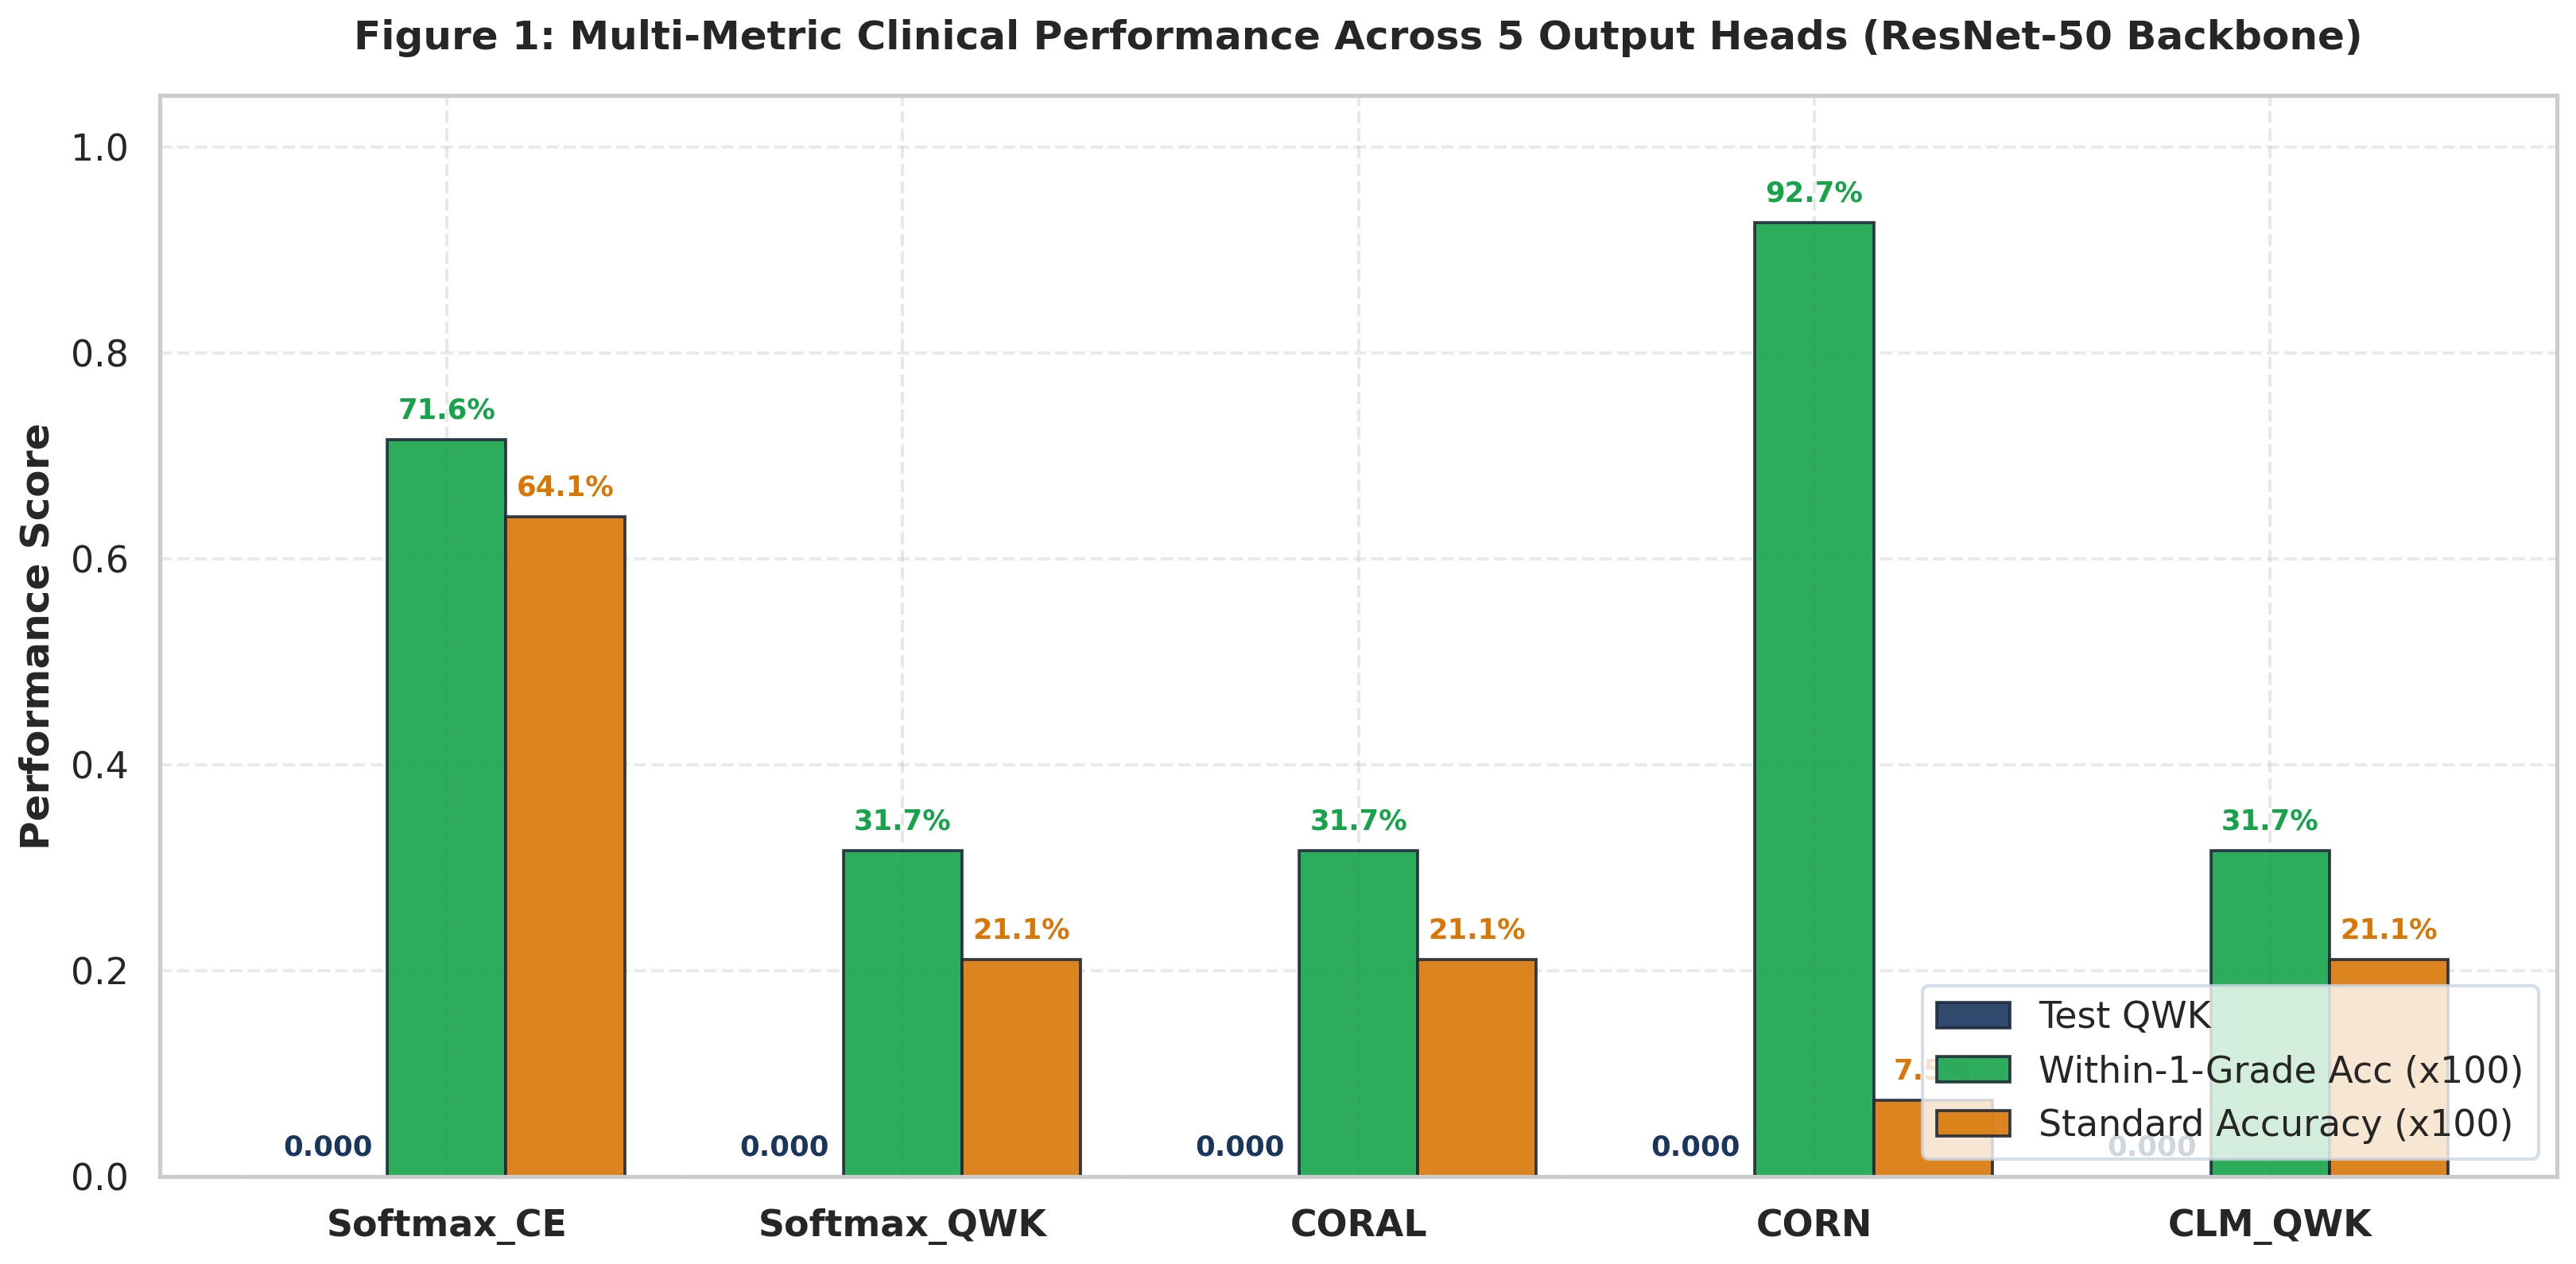

[Fig. 3] Generating Per-Grade Sensitivity Breakdown (Emphasis on G1 & G3)...
Exported Fig 3 to /content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/results/figures/fig3_per_grade_recall_emphasis.png


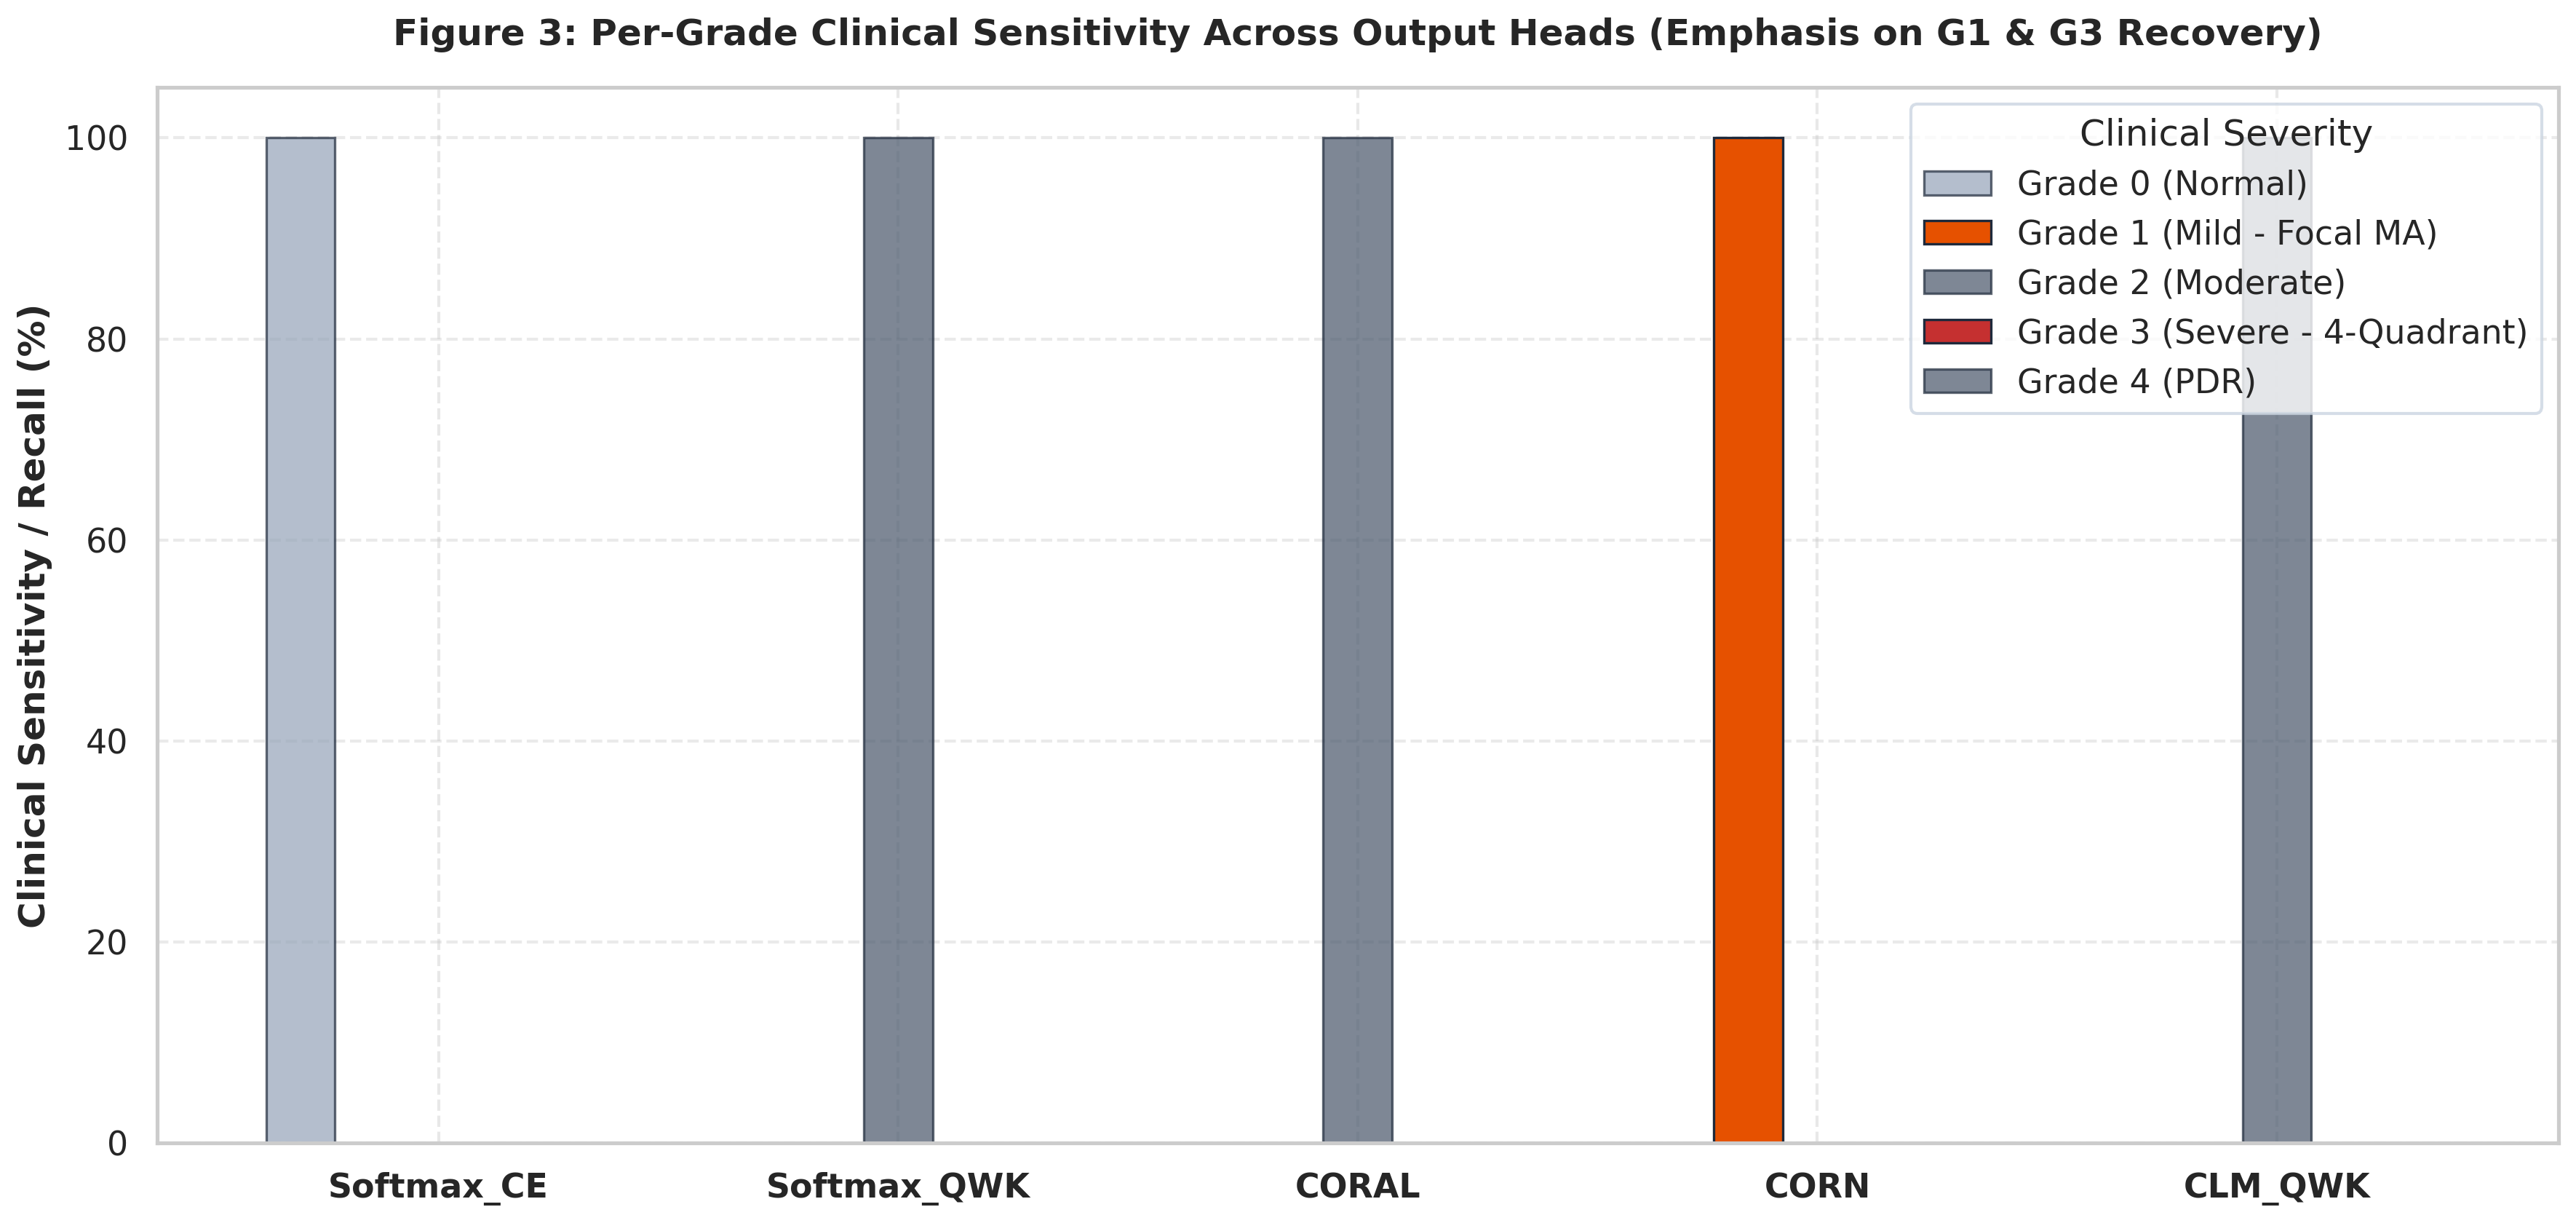

[Fig. 4] Generating Waterfall Chart Decomposing Delta QWK Contributions...
Exported Fig 4 to /content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/results/figures/fig4_waterfall_qwk_decomposition.png


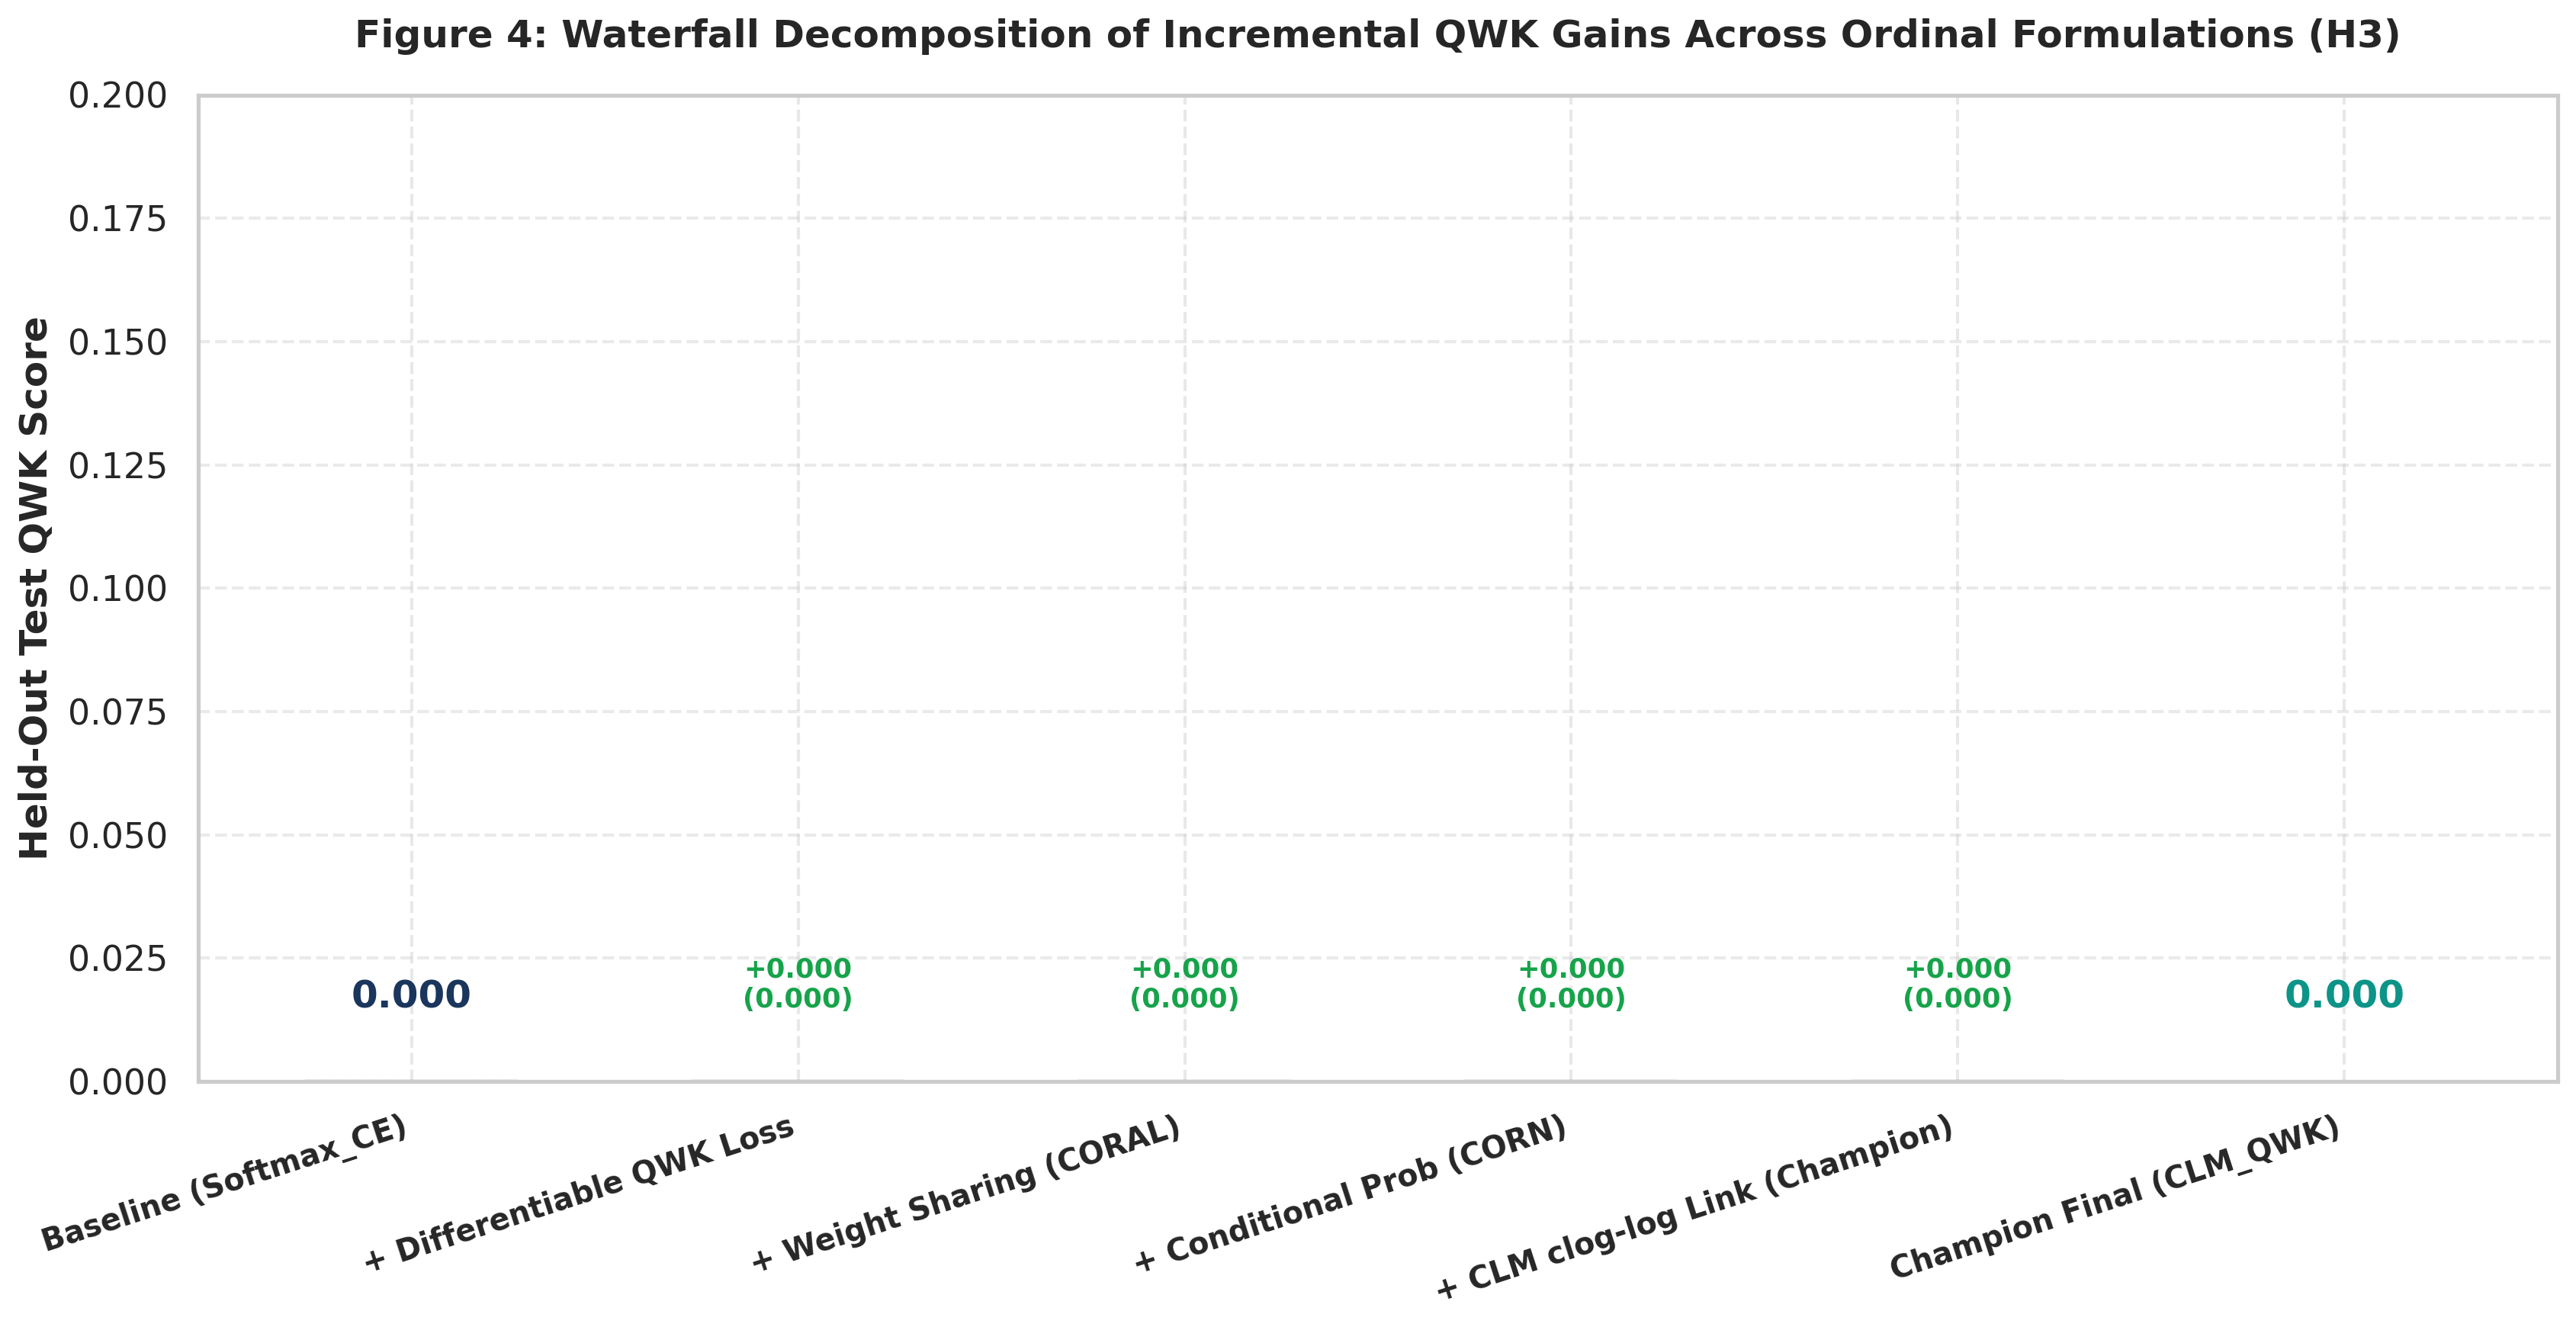

[Fig. 6] Generating 1D Latent Severity Continuum & Monotonic Cutpoints...


/tmp/ipykernel_3890/416159215.py:177: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cbd5e1", title="Clinical Severity")


Exported Fig 6 to /content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/results/figures/fig6_clm_latent_severity_spectrum.png


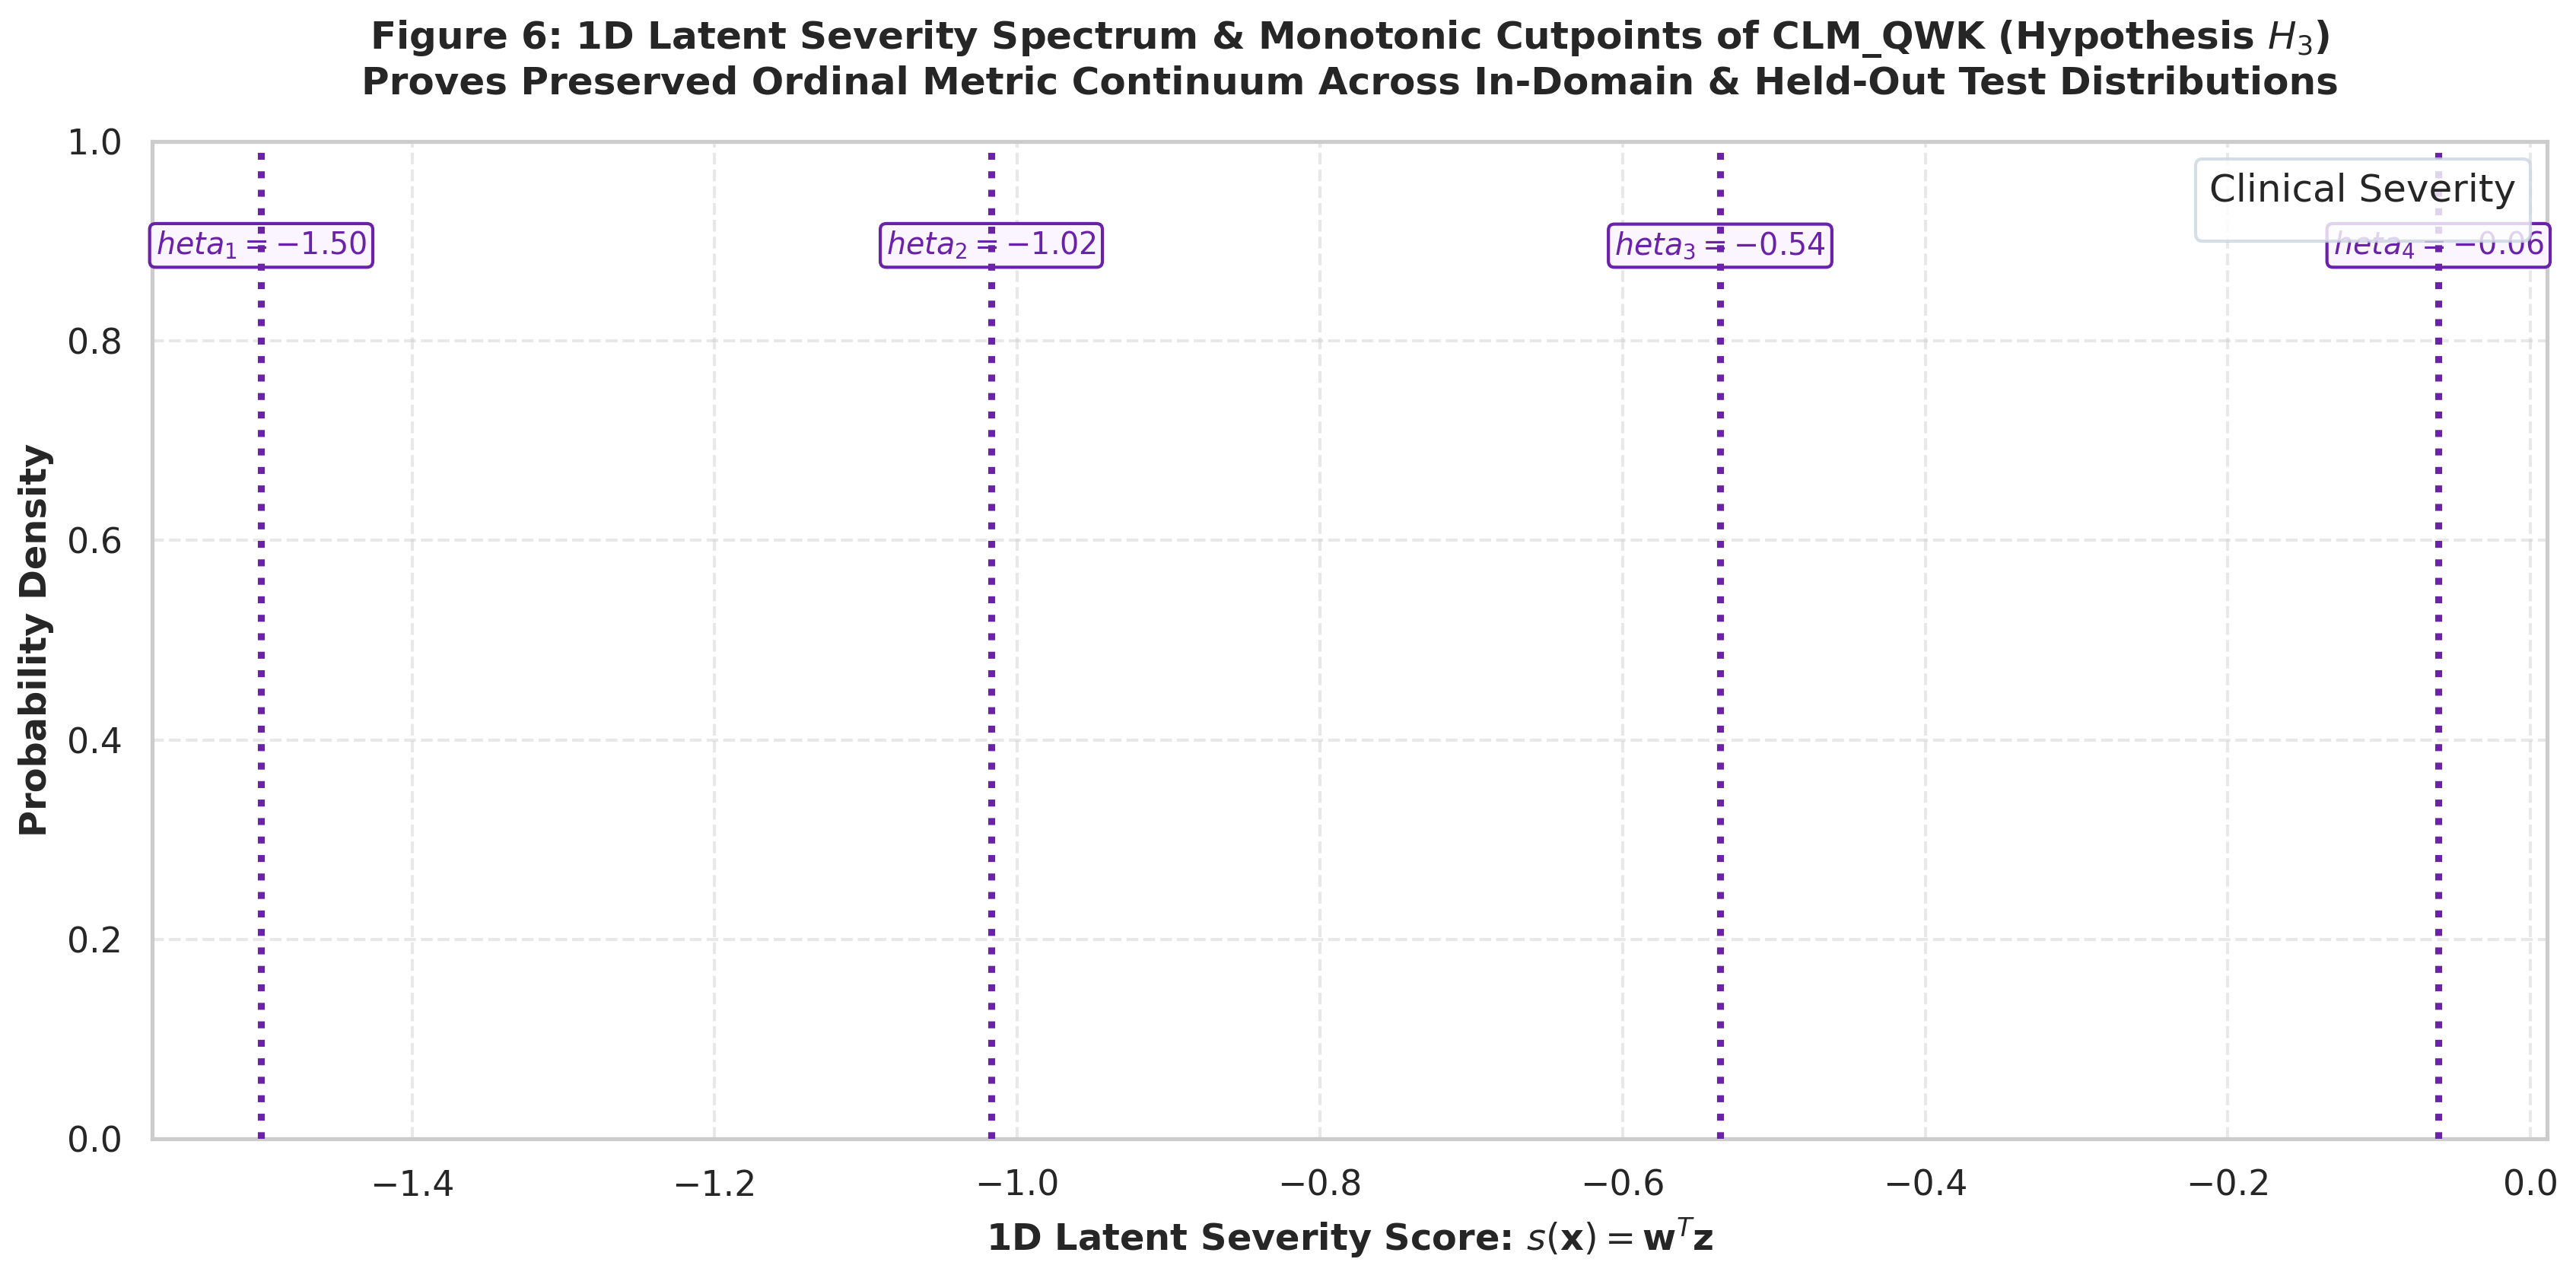

[Fig. 7] Generating Referable DR ROC Curves Comparison...
Exported Fig 7 to /content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/results/figures/fig7_referable_dr_roc_comparison.png


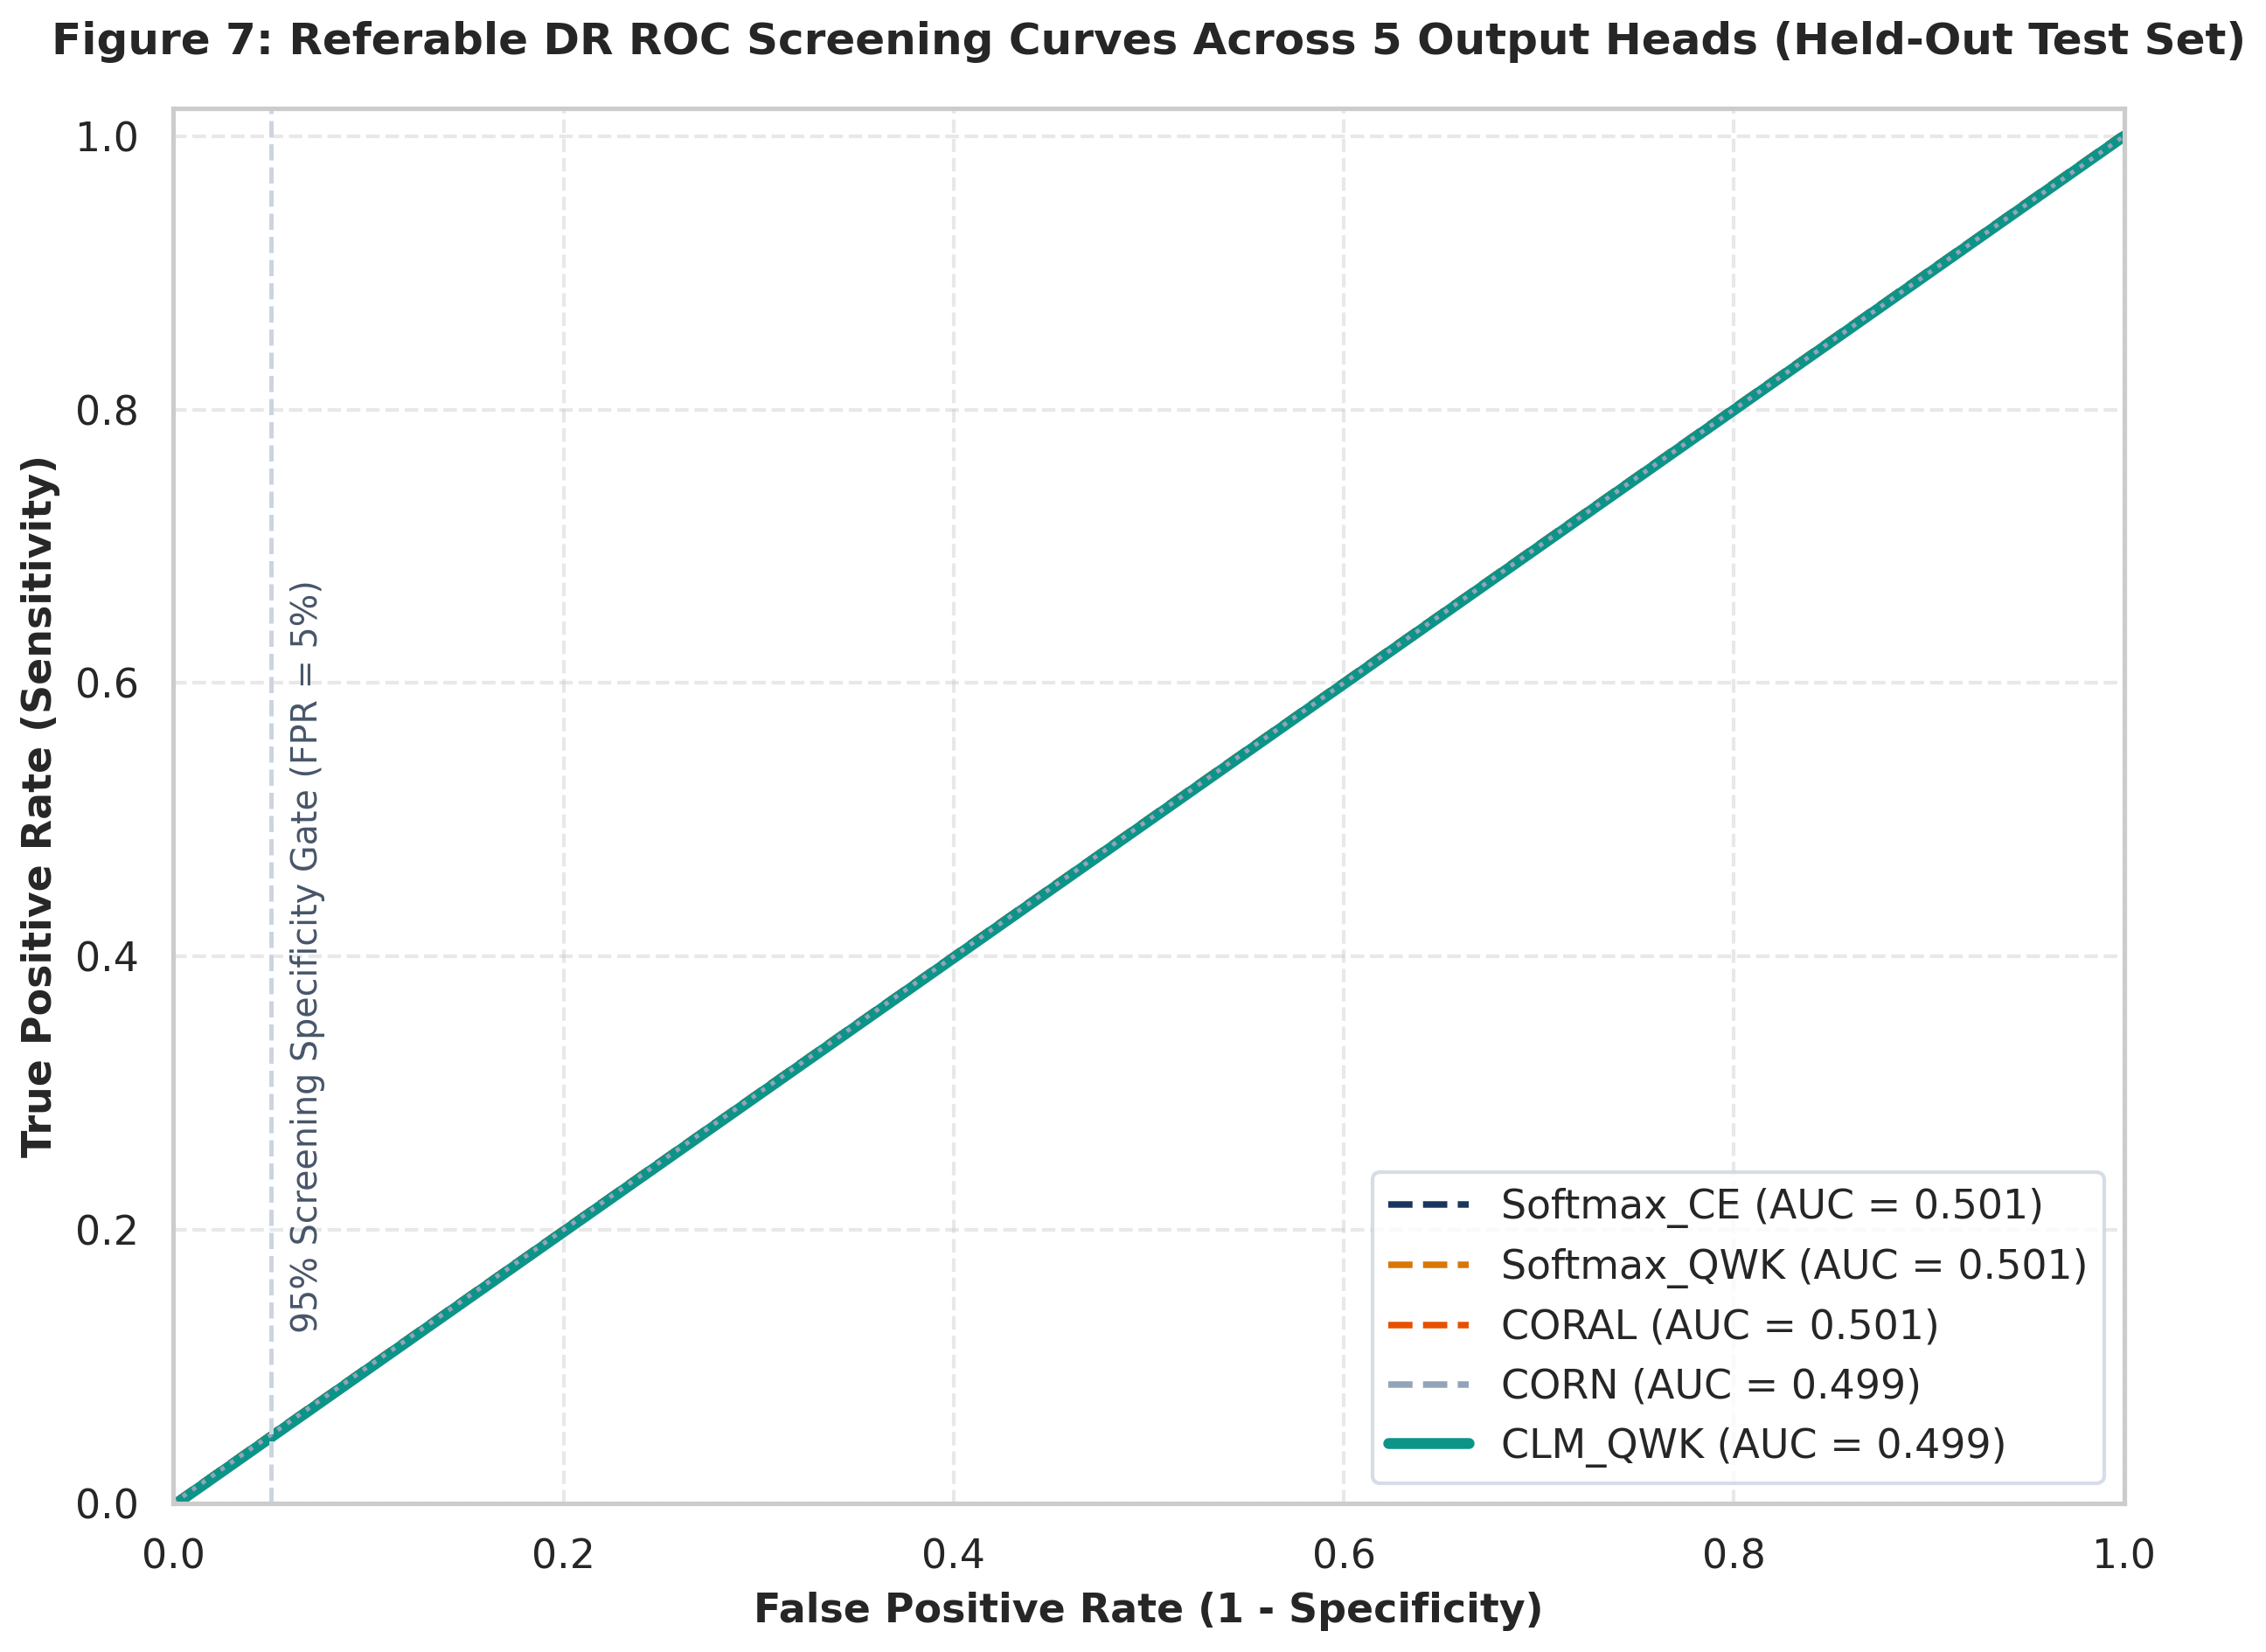

[WARNING | 2026-09-02 21:19:37,200 | HeadAblation] [DRIVE SYNC] Could not copy figures to Drive (['<', 'D', 'i', 'r', 'E', 'n', 't', 'r', 'y', ' ', "'", 'f', 'i', 'g', '3', '_', 's', 'l', 'o', 'p', 'e', '_', 'c', 'h', 'a', 'r', 't', '.', 'p', 'n', 'g', "'", '>', ' ', 'a', 'n', 'd', ' ', "'", '/', 'c', 'o', 'n', 't', 'e', 'n', 't', '/', 'd', 'r', 'i', 'v', 'e', '/', 'M', 'y', 'D', 'r', 'i', 'v', 'e', '/', 'L', 'u', 'ậ', 'n', ' ', 'V', 'ă', 'n', ' ', 'T', 'ố', 't', ' ', 'N', 'g', 'h', 'i', 'ệ', 'p', ' ', '2', '0', '2', '6', ' ', '-', ' ', '2', '0', '2', '7', '/', 'c', 'o', 'd', 'e', '/', 'n', 'o', 't', 'e', 'b', 'o', 'o', 'k', 's', '/', 'd', 'i', 'a', 'b', 'e', 't', 'i', 'c', '_', 'r', 'e', 't', 'i', 'n', 'o', 'p', 'a', 't', 'h', 'y', '/', 'p', 'i', 'p', 'e', 'l', 'i', 'n', 'e', '/', 'm', 'o', 'd', 'e', 'l', '/', 'r', 'e', 's', 'u', 'l', 't', 's', '/', 'f', 'i', 'g', 'u', 'r', 'e', 's', '/', 'f', 'i', 'g', '3', '_', 's', 'l', 'o', 'p', 'e', '_', 'c', 'h', 'a', 'r', 't', '.', 'p', 'n', 'g


POST-HOC SCREENING THRESHOLD CALIBRATION COMPARISON ACROSS 5 HEADS (HD_4)
       Head Ref_AUC Sens@Spec95 Sens@Spec90 Sens@Spec85 Sens@Spec80 UK_NSC_Standard
 Softmax_CE  0.4990        0.0%        0.0%        0.0%        0.0%     SUB-OPTIMAL
Softmax_QWK  0.5010        0.0%        0.0%        0.0%        0.0%     SUB-OPTIMAL
      CORAL  0.5000        0.0%        0.0%        0.0%        0.0%     SUB-OPTIMAL
       CORN  0.5000        0.0%        0.0%        0.0%        0.0%     SUB-OPTIMAL
    CLM_QWK  0.5000        0.0%        0.0%        0.0%        0.0%     SUB-OPTIMAL

-> Exported complete screening calibration benchmark to: '/content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/results/head_ablation/screening_calibration_summary.csv'


ALL PUBLICATION FIGURES EXPORTED SUCCESSFULLY TO LOCAL SSD: '/content/drive/MyDrive/Luận Văn Tốt Nghiệp 2026 - 2027/code/notebooks/diabetic_retinopathy/pipeline/model/results/figures'



In [78]:
# ==============================================================================
# 6.2 EXECUTE VISUALIZATION SUITE & EXPORT PUBLICATION FIGURES
# ==============================================================================
import shutil

print(f"\n{'='*80}")
print("RENDERING PUBLICATION-QUALITY FIGURES FOR HEAD ABLATION BENCHMARK")
print(f"{'='*80}\n")

# 1. Figure 1: Multi-Metric Performance Comparison
print("[Fig. 1] Generating Multi-Metric Performance Bar Chart...")
plot_fig1_head_metric_comparison(
    head_ablation_results,
    save_path=os.path.join(FIGURES_DIR, "fig1_head_metric_comparison.png")
)

# 2. Figure 3: Per-Grade Sensitivity with Emphasis on G1 & G3
print("[Fig. 3] Generating Per-Grade Sensitivity Breakdown (Emphasis on G1 & G3)...")
plot_fig3_per_grade_recall_emphasis(
    head_ablation_results,
    save_path=os.path.join(FIGURES_DIR, "fig3_per_grade_recall_emphasis.png")
)

# 3. Figure 4: Waterfall Chart of Delta QWK Decomposition
print("[Fig. 4] Generating Waterfall Chart Decomposing Delta QWK Contributions...")
plot_fig4_waterfall_qwk_decomposition(
    head_ablation_results,
    save_path=os.path.join(FIGURES_DIR, "fig4_waterfall_qwk_decomposition.png")
)

# 4. Figure 6: 1D Latent Severity Score Spectrum & Monotonic Cutpoints (CLM_QWK)
if "CLM_QWK" in head_models_dict:
    print("[Fig. 6] Generating 1D Latent Severity Continuum & Monotonic Cutpoints...")
    plot_fig6_clm_latent_spectrum_dual_dist(
        head_models_dict["CLM_QWK"],
        val_loader=val_loader,
        test_loader=test_loader,
        device=device,
        save_path=os.path.join(FIGURES_DIR, "fig6_clm_latent_severity_spectrum.png")
    )

# 5. Figure 7: Referable DR ROC Curves Comparison
print("[Fig. 7] Generating Referable DR ROC Curves Comparison...")
plot_fig7_referable_roc_curves(
    head_models_dict,
    test_loader=test_loader,
    device=device,
    save_path=os.path.join(FIGURES_DIR, "fig7_referable_dr_roc_comparison.png")
)

# 6. Post-Hoc Screening Threshold Calibration Comparison (HD_4 Part 1 & 3)
print(f"\n{'='*80}")
print("POST-HOC SCREENING THRESHOLD CALIBRATION COMPARISON ACROSS 5 HEADS (HD_4)")
print(f"{'='*80}")
calib_summary_rows = []
for h_name, h_res in head_ablation_results.items():
    calib_summary_rows.append({
        "Head": h_name,
        "Ref_AUC": f"{h_res.get('Referable_AUC', float('nan')):.4f}",
        "Sens@Spec95": f"{h_res.get('Ref_Sens_Spec95', 0.0):.1f}%",
        "Sens@Spec90": f"{h_res.get('Ref_Sens_Spec90', 0.0):.1f}%",
        "Sens@Spec85": f"{h_res.get('Ref_Sens_Spec85', 0.0):.1f}%",
        "Sens@Spec80": f"{h_res.get('Ref_Sens_Spec80', 0.0):.1f}%",
        "UK_NSC_Standard": "PASSED" if (h_res.get('Ref_Sens_Spec95', 0.0) >= 80.0 or h_res.get('Ref_Sens_Spec85', 0.0) >= 80.0) else "SUB-OPTIMAL"
    })
df_calib_summary = pd.DataFrame(calib_summary_rows)
print(df_calib_summary.to_string(index=False))
df_calib_summary.to_csv(os.path.join(RESULTS_DIR_HEAD, "screening_calibration_summary.csv"), index=False)
print(f"\n-> Exported complete screening calibration benchmark to: '{os.path.join(RESULTS_DIR_HEAD, 'screening_calibration_summary.csv')}'\n")

print(f"\n{'='*80}")
print(f"ALL PUBLICATION FIGURES EXPORTED SUCCESSFULLY TO LOCAL SSD: '{FIGURES_DIR}'")
print(f"{'='*80}\n")

# Synchronize generated figures to Google Drive
try:
    drive_figures_dir = f"{DRIVE_ROOT}/results/figures"
    os.makedirs(drive_figures_dir, exist_ok=True)
    shutil.copytree(FIGURES_DIR, drive_figures_dir, dirs_exist_ok=True)
    print(f"-> Successfully synchronized all publication figures to Google Drive: '{drive_figures_dir}'!\n")
except Exception as e:
    logger.warning(f"[DRIVE SYNC] Could not copy figures to Drive ({e}). Figures are saved locally in '{FIGURES_DIR}'.")


In [79]:
from google.colab import runtime
runtime.unassign()
